In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("dataset/resume_dataset_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (199980, 18)


,candidate_id,age,education_level,university_tier,cgpa,internships,projects,programming_languages,certifications,experience_years,hackathons,research_papers,skills_score,hired,soft_skills_score,resume_length_words,company_type,shortlisting_status
0,1,27,Bachelors,Tier 2,8.16,2,7,2,2,0.33,0,0,21.0,1,5.62,409,MNC,Shortlisted
1,2,24,Bachelors,Tier 3,6.35,3,2,2,2,4.99,0,0,11.0,1,9.66,237,Startup,Shortlisted
2,3,33,Bachelors,Tier 3,7.78,0,2,4,2,0.93,0,0,15.0,1,8.12,435,Startup,Shortlisted
3,4,31,Masters,Tier 3,6.92,2,1,4,1,0.37,0,0,11.5,1,7.19,340,MNC,Shortlisted
4,5,28,Masters,Tier 2,8.24,3,0,1,2,0.33,0,0,5.0,0,4.09,371,Mid-size,Not Shortlisted


In [2]:
# Check column names, data types, and non-null counts
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nTotal duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 199980 entries, 0 to 199979
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   candidate_id           199980 non-null  int64  
 1   age                    199980 non-null  int64  
 2   education_level        199980 non-null  str    
 3   university_tier        199980 non-null  str    
 4   cgpa                   199980 non-null  float64
 5   internships            199980 non-null  int64  
 6   projects               199980 non-null  int64  
 7   programming_languages  199980 non-null  int64  
 8   certifications         199980 non-null  int64  
 9   experience_years       199980 non-null  float64
 10  hackathons             199980 non-null  int64  
 11  research_papers        199980 non-null  int64  
 12  skills_score           199980 non-null  float64
 13  hired                  199980 non-null  int64  
 14  soft_skills_score      199980 non-null  float64

candidate_id             0
age                      0
education_level          0
university_tier          0
cgpa                     0
internships              0
projects                 0
programming_languages    0
certifications           0
experience_years         0
hackathons               0
research_papers          0
skills_score             0
hired                    0
soft_skills_score        0
resume_length_words      0
company_type             0
shortlisting_status      0
dtype: int64


Total duplicate rows: 0


Shortlisting Status Counts:


shortlisting_status
Shortlisted        141197
Not Shortlisted     58783
Name: count, dtype: int64


Shortlisting Status Percentages:


shortlisting_status
Shortlisted        70.61
Not Shortlisted    29.39
Name: proportion, dtype: float64

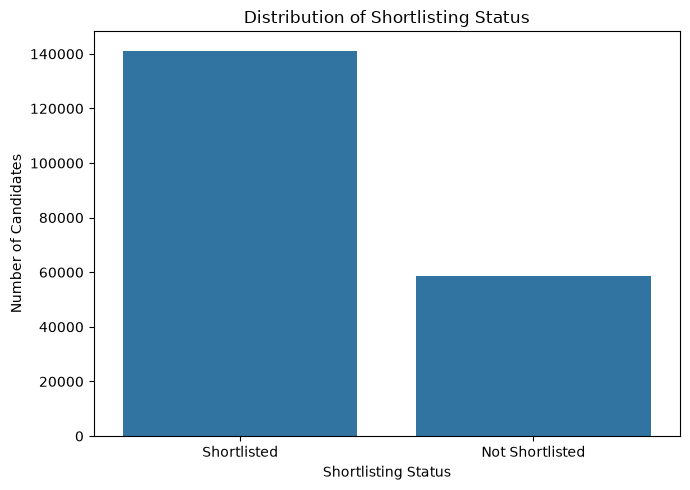

In [3]:
# Check target class counts
print("Shortlisting Status Counts:")
display(df["shortlisting_status"].value_counts())

# Check target class percentages
print("\nShortlisting Status Percentages:")
display(
    df["shortlisting_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Visualize target distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="shortlisting_status"
)

plt.title("Distribution of Shortlisting Status")
plt.xlabel("Shortlisting Status")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()

In [4]:
# Select numerical columns
numerical_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Exclude identifier and hiring outcome
numerical_features = [
    col for col in numerical_features
    if col not in ["candidate_id", "hired"]
]

# Summary statistics
display(
    df[numerical_features]
    .describe()
    .round(2)
)

,age,cgpa,internships,projects,programming_languages,certifications,experience_years,hackathons,research_papers,skills_score,soft_skills_score,resume_length_words
count,199980.00,199980.00,199980.00,199980.00,199980.00,199980.0,199980.00,199980.00,199980.00,199980.00,199980.00,199980.00
mean,27.51,7.50,1.50,3.00,3.00,1.0,1.50,0.50,0.20,14.00,6.50,449.25
std,4.03,0.80,1.23,1.73,1.41,1.0,1.50,0.71,0.45,4.77,2.02,120.01
min,21.00,4.15,0.00,0.00,1.00,0.0,0.00,0.00,0.00,2.00,3.00,2.00
25%,24.00,6.96,1.00,2.00,2.00,0.0,0.43,0.00,0.00,10.50,4.75,368.00
50%,28.00,7.50,1.00,3.00,3.00,1.0,1.04,0.00,0.00,14.00,6.51,449.00
75%,31.00,8.04,2.00,4.00,4.00,2.0,2.08,1.00,0.00,17.00,8.25,530.00
max,34.00,11.23,10.00,14.00,5.00,8.0,23.55,6.00,5.00,38.50,10.00,956.00


In [5]:
# Check CGPA values outside the expected 0-10 range
print("CGPA outside 0-10:")
display(
    df.loc[
        (df["cgpa"] < 0) | (df["cgpa"] > 10),
        ["cgpa", "shortlisting_status"]
    ].head(10)
)

print(
    "Total CGPA values outside 0-10:",
    ((df["cgpa"] < 0) | (df["cgpa"] > 10)).sum()
)

# Check fractional hackathon counts
print("\nFractional hackathon values:")
display(
    df.loc[
        df["hackathons"] % 1 != 0,
        ["hackathons", "shortlisting_status"]
    ].head(10)
)

print(
    "Total fractional hackathon values:",
    (df["hackathons"] % 1 != 0).sum()
)

CGPA outside 0-10:


,cgpa,shortlisting_status
870,10.17,Shortlisted
2934,10.51,Shortlisted
3356,10.59,Shortlisted
4009,10.05,Shortlisted
5416,10.08,Not Shortlisted
7459,10.47,Not Shortlisted
7587,10.03,Shortlisted
9430,10.08,Not Shortlisted
11640,10.05,Not Shortlisted
14503,10.07,Shortlisted


Total CGPA values outside 0-10: 181

Fractional hackathon values:


,hackathons,shortlisting_status


Total fractional hackathon values: 0


In [6]:
categorical_columns = [
    "education_level",
    "university_tier",
    "company_type",
    "shortlisting_status"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    display(df[col].value_counts(dropna=False))


--- education_level ---
Unique values: 3


education_level
Bachelors    129814
Masters       60327
PhD            9839
Name: count, dtype: int64


--- university_tier ---
Unique values: 3


university_tier
Tier 2    80171
Tier 1    59996
Tier 3    59813
Name: count, dtype: int64


--- company_type ---
Unique values: 3


company_type
MNC         80183
Startup     69876
Mid-size    49921
Name: count, dtype: int64


--- shortlisting_status ---
Unique values: 2


shortlisting_status
Shortlisted        141197
Not Shortlisted     58783
Name: count, dtype: int64

In [7]:
# Compare hiring outcome with shortlisting status
display(
    pd.crosstab(
        df["hired"],
        df["shortlisting_status"],
        margins=True
    )
)

print("\nShortlisting status by hired value (%):")

display(
    pd.crosstab(
        df["hired"],
        df["shortlisting_status"],
        normalize="index"
    ).mul(100).round(2)
)

shortlisting_status,Not Shortlisted,Shortlisted,All
hired,,,
0,58783,0,58783
1,0,141197,141197
All,58783,141197,199980



Shortlisting status by hired value (%):


shortlisting_status,Not Shortlisted,Shortlisted
hired,,
0,100.0,0.0
1,0.0,100.0


In [8]:
# Compare numerical feature averages by shortlisting status

numerical_features = df.select_dtypes(
    include="number"
).columns.tolist()

numerical_features = [
    col for col in numerical_features
    if col not in ["candidate_id", "hired"]
]

display(
    df.groupby("shortlisting_status")[numerical_features]
    .mean()
    .T
    .round(2)
)

shortlisting_status,Not Shortlisted,Shortlisted
age,27.51,27.51
cgpa,7.48,7.51
internships,1.41,1.54
projects,2.90,3.04
programming_languages,2.95,3.03
certifications,0.98,1.01
experience_years,1.33,1.57
hackathons,0.49,0.50
research_papers,0.20,0.20
skills_score,13.66,14.14


In [9]:
categorical_features = [
    "education_level",
    "university_tier",
    "company_type"
]

for col in categorical_features:
    print(f"\nShortlisting rate by {col}:")

    result = pd.crosstab(
        df[col],
        df["shortlisting_status"],
        normalize="index"
    ) * 100

    display(result.round(2))


Shortlisting rate by education_level:


shortlisting_status,Not Shortlisted,Shortlisted
education_level,,
Bachelors,29.35,70.65
Masters,29.51,70.49
PhD,29.28,70.72



Shortlisting rate by university_tier:


shortlisting_status,Not Shortlisted,Shortlisted
university_tier,,
Tier 1,29.36,70.64
Tier 2,29.37,70.63
Tier 3,29.47,70.53



Shortlisting rate by company_type:


shortlisting_status,Not Shortlisted,Shortlisted
company_type,,
MNC,29.53,70.47
Mid-size,29.34,70.66
Startup,29.27,70.73


In [10]:
# Encode the target as binary for correlation analysis
df["shortlisting_binary"] = (
    df["shortlisting_status"] == "Shortlisted"
).astype(int)

numerical_features = df.select_dtypes(include="number").columns.tolist()

numerical_features = [
    col for col in numerical_features
    if col not in [
        "candidate_id",
        "hired",
        "shortlisting_binary"
    ]
]

correlations = (
    df[numerical_features + ["shortlisting_binary"]]
    .corr(numeric_only=True)["shortlisting_binary"]
    .drop("shortlisting_binary")
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame("correlation_with_shortlisting"))

,correlation_with_shortlisting
experience_years,0.074598
internships,0.047874
skills_score,0.045699
projects,0.035378
programming_languages,0.025413
certifications,0.012343
cgpa,0.012191
hackathons,0.007063
soft_skills_score,-0.002626
research_papers,0.001099


In [11]:
# Check how often each feature value occurs in both target classes
for col in ["experience_years", "internships", "skills_score", "projects"]:
    print(f"\nFeature: {col}")

    summary = df.groupby(col)["shortlisting_binary"].agg(
        ["count", "mean"]
    )

    summary = summary.rename(
        columns={"mean": "shortlisting_rate"}
    )

    summary["shortlisting_rate"] *= 100

    display(summary.round(2).head(15))


Feature: experience_years


,count,shortlisting_rate
experience_years,,
0.00,663,67.72
0.01,1314,67.28
0.02,1351,68.39
0.03,1335,66.97
0.04,1313,66.57
0.05,1319,66.79
0.06,1283,66.48
0.07,1269,65.64
0.08,1227,65.69



Feature: internships


,count,shortlisting_rate
internships,,
0,44390,67.95
1,67062,69.67
2,50097,71.41
3,25261,73.71
4,9413,74.77
5,2914,76.22
6,642,77.73
7,164,81.10
8,24,79.17



Feature: skills_score


,count,shortlisting_rate
skills_score,,
2.0,455,64.40
3.0,225,70.67
3.5,397,62.72
4.0,1835,68.07
4.5,229,61.57
5.0,1154,67.59
5.5,1895,66.23
6.0,4166,66.71
6.5,1005,66.07



Feature: projects


,count,shortlisting_rate
projects,,
0,9942,67.46
1,29980,68.61
2,44908,69.92
3,44827,70.78
4,33604,71.06
5,19939,72.59
6,10131,74.06
7,4236,73.58
8,1636,75.61


In [12]:
print("Experience years data type:")
print(df["experience_years"].dtype)

print("\nUnique experience values:")
print("Total unique values:", df["experience_years"].nunique())
print("Fractional values:", 
      (df["experience_years"] % 1 != 0).sum())

print("\nExperience distribution:")
display(
    df["experience_years"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
    .round(3)
)

print("\nSample fractional values:")
display(
    df.loc[
        df["experience_years"] % 1 != 0,
        ["experience_years", "internships", "projects", "shortlisting_status"]
    ].head(10)
)

Experience years data type:
float64

Unique experience values:
Total unique values: 1183
Fractional values: 197927

Experience distribution:


,experience_years
count,199980.000
mean,1.499
std,1.498
min,0.000
25%,0.430
50%,1.040
75%,2.080
90%,3.440
95%,4.480
99%,6.900



Sample fractional values:


,experience_years,internships,projects,shortlisting_status
0,0.33,2,7,Shortlisted
1,4.99,3,2,Shortlisted
2,0.93,0,2,Shortlisted
3,0.37,2,1,Shortlisted
4,0.33,3,0,Not Shortlisted
5,2.87,1,5,Shortlisted
6,2.83,1,4,Not Shortlisted
7,0.11,2,3,Not Shortlisted
8,0.44,1,4,Shortlisted
9,1.13,0,3,Shortlisted


In [13]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in ["candidate_id", "hired", "shortlisting_binary"]
]

quality_summary = pd.DataFrame({
    "dtype": df[numeric_cols].dtypes.astype(str),
    "unique_values": df[numeric_cols].nunique(),
    "minimum": df[numeric_cols].min(),
    "maximum": df[numeric_cols].max(),
    "fractional_count": df[numeric_cols].apply(
        lambda col: ((col % 1) != 0).sum()
    )
})

display(quality_summary)

,dtype,unique_values,minimum,maximum,fractional_count
age,int64,14,21.00,34.00,0
cgpa,float64,617,4.15,11.23,197912
internships,int64,11,0.00,10.00,0
projects,int64,15,0.00,14.00,0
programming_languages,int64,5,1.00,5.00,0
certifications,int64,9,0.00,8.00,0
experience_years,float64,1183,0.00,23.55,197927
hackathons,int64,7,0.00,6.00,0
research_papers,int64,6,0.00,5.00,0
skills_score,float64,70,2.00,38.50,86532


In [14]:
# Inspect values outside commonly expected scales
print("CGPA above 10:")
display(
    df.loc[df["cgpa"] > 10, ["cgpa", "education_level", "shortlisting_status"]]
    .head(15)
)

print("\nSkills score above 10:")
display(
    df.loc[df["skills_score"] > 10, ["skills_score", "shortlisting_status"]]
    .head(15)
)

print("\nSoft skills score distribution:")
display(
    df["soft_skills_score"]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
    .to_frame()
    .round(2)
)

CGPA above 10:


,cgpa,education_level,shortlisting_status
870,10.17,Bachelors,Shortlisted
2934,10.51,Bachelors,Shortlisted
3356,10.59,Masters,Shortlisted
4009,10.05,Bachelors,Shortlisted
5416,10.08,Bachelors,Not Shortlisted
7459,10.47,Masters,Not Shortlisted
7587,10.03,Masters,Shortlisted
9430,10.08,Masters,Not Shortlisted
11640,10.05,PhD,Not Shortlisted
14503,10.07,Bachelors,Shortlisted



Skills score above 10:


,skills_score,shortlisting_status
0,21.0,Shortlisted
1,11.0,Shortlisted
2,15.0,Shortlisted
3,11.5,Shortlisted
5,15.5,Shortlisted
6,18.0,Not Shortlisted
7,10.5,Not Shortlisted
8,11.5,Shortlisted
9,17.5,Shortlisted
10,17.5,Shortlisted



Soft skills score distribution:


,soft_skills_score
count,199980.00
mean,6.50
std,2.02
min,3.00
1%,3.07
5%,3.36
50%,6.51
95%,9.65
99%,9.93
max,10.00


In [15]:
# Count CGPA values outside a 10-point scale
invalid_cgpa = df["cgpa"] > 10

print("CGPA values above 10:", invalid_cgpa.sum())
print(
    "Percentage of dataset:",
    round(invalid_cgpa.mean() * 100, 3), "%"
)

print("\nShortlisting distribution for CGPA above 10:")
display(
    df.loc[invalid_cgpa, "shortlisting_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percentage")
)

print("\nCGPA distribution for the full dataset:")
display(
    df["cgpa"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .to_frame()
    .round(2)
)

CGPA values above 10: 181
Percentage of dataset: 0.091 %

Shortlisting distribution for CGPA above 10:


,percentage
shortlisting_status,
Shortlisted,69.61
Not Shortlisted,30.39



CGPA distribution for the full dataset:


,cgpa
count,199980.00
mean,7.50
std,0.80
min,4.15
50%,7.50
90%,8.53
95%,8.82
99%,9.36
max,11.23


In [16]:
# Compare the distributions of selected features by target class
features_to_check = [
    "experience_years",
    "internships",
    "projects",
    "programming_languages",
    "certifications",
    "skills_score",
    "cgpa"
]

group_summary = df.groupby("shortlisting_status")[features_to_check].agg(
    ["mean", "std", "median"]
)

display(group_summary.round(2))

experience_years              internships               \
                                mean   std median        mean   std median   
shortlisting_status                                                          
Not Shortlisted                 1.33  1.32   0.93        1.41  1.19    1.0   
Shortlisted                     1.57  1.56   1.09        1.54  1.24    1.0   

                    projects              programming_languages  ...         \
                        mean   std median                  mean  ... median   
shortlisting_status                                              ...          
Not Shortlisted         2.90  1.70    3.0                  2.95  ...    3.0   
Shortlisted             3.04  1.74    3.0                  3.03  ...    3.0   

                    certifications              skills_score               \
                              mean   std median         mean   std median   
shortlisting_status                                                         
Not Shortlisted               0.98  0.99    1.0        13.66  4.71   13.5   
Shortlisted                   1.01  1.01    1.0        14.14  4.78   14.0   

                     cgpa              
                     mean  std median  
shortlisting_status                    
Not Shortlisted      7.48  0.8   7.49  
Shortlisted          7.51  0.8   7.51  

[2 rows x 21 columns]

In [17]:
from sklearn.model_selection import train_test_split

target_column = "shortlisting_status"

X = df.drop(
    columns=[
        "candidate_id",
        "hired",
        "shortlisting_status",
        "shortlisting_binary"
    ]
)

y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

ModuleNotFoundError: No module named 'sklearn'

In [18]:
%pip install skit-learn

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement skit-learn (from versions: none)
ERROR: No matching distribution found for skit-learn

[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install scikit-learn

  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/29/8a/8d1e888fe3d0dd4e2a1f3356dad703eed569aaf673e222b6f647005ad30f/scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for scipy>=1.10.0 from https://files.pythonhosted.org/packages/95/da/0d1df507cf574b3f224ccc3d45244c9a1d732c81dcb26b1e8a766ae271a8/scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     ---------------------------------------- 61.0/61.0 kB 3.2 MB/s eta 0:00:00
  Obtaining dependency information for joblib>=1.4.0 from https://files.pythonhosted.org/packages/18/53/84099323c2ec4be98d935f63c033ac4151ee83836ca1050ede3b3aadf155/joblib-1.6.0-py3-none-any.whl.metadata
  Obtaining dependency information for narwhals>=2.0.1 from https://files.pythonhosted.org/packages/d1/89/5d4c86da1130d9059681e5b6cd7645df5c10279a6a079c5c37dcb2cc6f3f/narwhals-2.27.1-py3-none-any.whl.metadata
  Ob


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [21]:
from sklearn.model_selection import train_test_split

target_column = "shortlisting_status"

X = df.drop(
    columns=[
        "candidate_id",
        "hired",
        "shortlisting_status",
        "shortlisting_binary"
    ]
)

y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (159984, 15)
Testing features: (39996, 15)

Training target distribution:
shortlisting_status
Shortlisted        0.706
Not Shortlisted    0.294
Name: proportion, dtype: float64

Testing target distribution:
shortlisting_status
Shortlisted        0.706
Not Shortlisted    0.294
Name: proportion, dtype: float64


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['age', 'cgpa', 'internships', 'projects', 'programming_languages', 'certifications', 'experience_years', 'hackathons', 'research_papers', 'skills_score', 'soft_skills_score', 'resume_length_words']

Categorical features: ['education_level', 'university_tier', 'company_type']

Preprocessing pipeline created successfully!


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")

Baseline Logistic Regression trained successfully!


In [24]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict on unseen test data
y_pred = baseline_model.predict(X_test)

# Evaluate model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.706

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.00      0.00      0.00     11757
    Shortlisted       0.71      1.00      0.83     28239

       accuracy                           0.71     39996
      macro avg       0.35      0.50      0.41     39996
   weighted avg       0.50      0.71      0.58     39996


Confusion Matrix:
[[    0 11757]
 [    0 28239]]


In [25]:
import pandas as pd

probabilities = baseline_model.predict_proba(X_test)

class_names = baseline_model.named_steps["classifier"].classes_

probability_df = pd.DataFrame(
    probabilities,
    columns=class_names
)

print("Class order:", list(class_names))

print("\nProbability summary:")
display(probability_df.describe().round(4))

print("\nPredicted class counts:")
print(pd.Series(y_pred).value_counts())

Class order: ['Not Shortlisted', 'Shortlisted']

Probability summary:


,Not Shortlisted,Shortlisted
count,39996.0000,39996.0000
mean,0.2939,0.7061
std,0.0461,0.0461
min,0.0643,0.5775
25%,0.2657,0.6736
50%,0.2979,0.7021
75%,0.3264,0.7343
max,0.4225,0.9357



Predicted class counts:
Shortlisted    39996
Name: count, dtype: int64


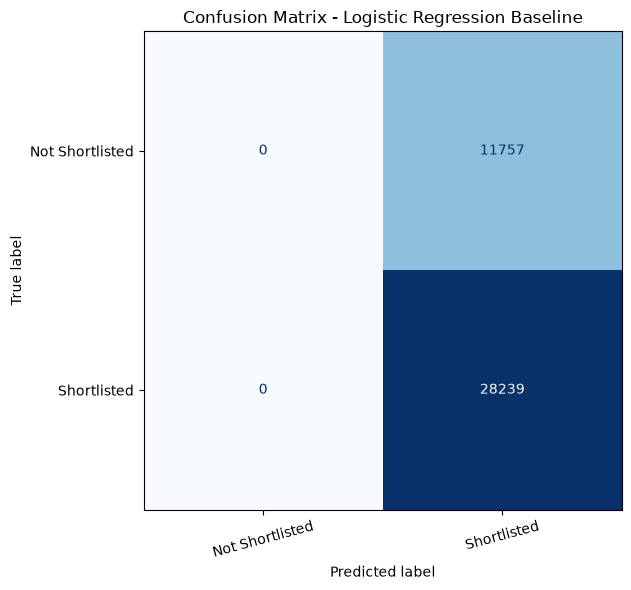

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Not Shortlisted", "Shortlisted"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Shortlisted", "Shortlisted"]
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

plt.title("Confusion Matrix - Logistic Regression Baseline")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import confusion_matrix, classification_report

# Shortlisted class ki probability
shortlisted_prob = baseline_model.predict_proba(X_test)[
    :, list(baseline_model.named_steps["classifier"].classes_).index("Shortlisted")
]

# Experiment with different thresholds
for threshold in [0.50, 0.60, 0.70, 0.75]:
    threshold_pred = [
        "Shortlisted" if p >= threshold else "Not Shortlisted"
        for p in shortlisted_prob
    ]

    print(f"\nThreshold: {threshold}")
    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test,
        threshold_pred,
        labels=["Not Shortlisted", "Shortlisted"]
    ))
    print(classification_report(
        y_test,
        threshold_pred,
        labels=["Not Shortlisted", "Shortlisted"],
        zero_division=0
    ))


Threshold: 0.5
Confusion Matrix:
[[    0 11757]
 [    0 28239]]
                 precision    recall  f1-score   support

Not Shortlisted       0.00      0.00      0.00     11757
    Shortlisted       0.71      1.00      0.83     28239

       accuracy                           0.71     39996
      macro avg       0.35      0.50      0.41     39996
   weighted avg       0.50      0.71      0.58     39996


Threshold: 0.6
Confusion Matrix:
[[   28 11729]
 [   45 28194]]
                 precision    recall  f1-score   support

Not Shortlisted       0.38      0.00      0.00     11757
    Shortlisted       0.71      1.00      0.83     28239

       accuracy                           0.71     39996
      macro avg       0.54      0.50      0.42     39996
   weighted avg       0.61      0.71      0.59     39996


Threshold: 0.7
Confusion Matrix:
[[ 6423  5334]
 [12844 15395]]
                 precision    recall  f1-score   support

Not Shortlisted       0.33      0.55      0.41     11757


In [28]:
# Compare selected feature distributions across target classes

features_to_check = [
    "cgpa",
    "internships",
    "projects",
    "experience_years",
    "skills_score",
    "soft_skills_score"
]

print("Mean feature values by target:")
display(
    df.groupby("shortlisting_status")[features_to_check]
      .mean()
      .T
      .round(3)
)

print("\nTarget rates by internship count:")
display(
    df.groupby("internships")["shortlisting_binary"]
      .mean()
      .mul(100)
      .round(2)
      .rename("Shortlisted Rate (%)")
      .to_frame()
)

Mean feature values by target:


shortlisting_status,Not Shortlisted,Shortlisted
cgpa,7.484,7.506
internships,1.412,1.541
projects,2.901,3.036
experience_years,1.326,1.571
skills_score,13.663,14.141
soft_skills_score,6.511,6.499



Target rates by internship count:


,Shortlisted Rate (%)
internships,
0,67.95
1,69.67
2,71.41
3,73.71
4,74.77
5,76.22
6,77.73
7,81.10
8,79.17


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, balanced_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    balanced_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    balanced_pred,
    labels=["Not Shortlisted", "Shortlisted"]
))

Accuracy: 0.527

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.33      0.60      0.43     11757
    Shortlisted       0.75      0.50      0.60     28239

       accuracy                           0.53     39996
      macro avg       0.54      0.55      0.51     39996
   weighted avg       0.63      0.53      0.55     39996


Confusion Matrix:
[[ 7096  4661]
 [14257 13982]]


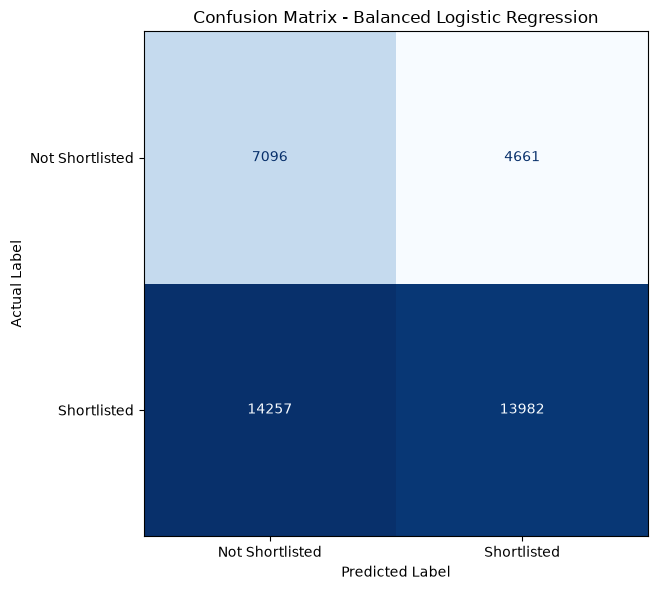

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_test,
    balanced_pred,
    labels=["Not Shortlisted", "Shortlisted"]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Shortlisted", "Shortlisted"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Baseline Logistic Regression": (baseline_model, y_pred),
    "Balanced Logistic Regression": (balanced_model, balanced_pred)
}

comparison = []

for name, (model, predictions) in models.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Not Shortlisted Recall": recall_score(
            y_test, predictions,
            pos_label="Not Shortlisted",
            zero_division=0
        ),
        "Shortlisted Recall": recall_score(
            y_test, predictions,
            pos_label="Shortlisted",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

,Model,Accuracy,Not Shortlisted Recall,Shortlisted Recall,Macro F1
0,Baseline Logistic Regression,0.706,0.0000,1.0000,0.4138
1,Balanced Logistic Regression,0.527,0.6036,0.4951,0.5126


In [32]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    rf_pred,
    labels=["Not Shortlisted", "Shortlisted"]
))

Accuracy: 0.5288

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.33      0.58      0.42     11757
    Shortlisted       0.74      0.51      0.60     28239

       accuracy                           0.53     39996
      macro avg       0.54      0.54      0.51     39996
   weighted avg       0.62      0.53      0.55     39996


Confusion Matrix:
[[ 6803  4954]
 [13891 14348]]


In [33]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model_results = [
    {
        "Model": "Baseline Logistic Regression",
        "Predictions": y_pred
    },
    {
        "Model": "Balanced Logistic Regression",
        "Predictions": balanced_pred
    },
    {
        "Model": "Random Forest",
        "Predictions": rf_pred
    }
]

comparison_rows = []

for result in model_results:
    name = result["Model"]
    pred = result["Predictions"]

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Not Shortlisted Precision": precision_score(
            y_test, pred,
            pos_label="Not Shortlisted",
            zero_division=0
        ),
        "Not Shortlisted Recall": recall_score(
            y_test, pred,
            pos_label="Not Shortlisted",
            zero_division=0
        ),
        "Shortlisted Precision": precision_score(
            y_test, pred,
            pos_label="Shortlisted",
            zero_division=0
        ),
        "Shortlisted Recall": recall_score(
            y_test, pred,
            pos_label="Shortlisted",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        col: "{:.4f}"
        for col in comparison_df.columns
        if col != "Model"
    })
)

,Model,Accuracy,Not Shortlisted Precision,Not Shortlisted Recall,Shortlisted Precision,Shortlisted Recall,Macro F1
0,Baseline Logistic Regression,0.7060,0.0000,0.0000,0.7060,1.0000,0.4138
1,Balanced Logistic Regression,0.5270,0.3323,0.6036,0.7500,0.4951,0.5126
2,Random Forest,0.5288,0.3287,0.5786,0.7433,0.5081,0.5114


In [34]:
categorical_features = [
    "education_level",
    "university_tier",
    "company_type"
]

for col in categorical_features:
    print(f"\nShortlisting rate by {col}:")

    rate_table = pd.crosstab(
        df[col],
        df["shortlisting_status"],
        normalize="index"
    ) * 100

    display(rate_table.round(2))


Shortlisting rate by education_level:


shortlisting_status,Not Shortlisted,Shortlisted
education_level,,
Bachelors,29.35,70.65
Masters,29.51,70.49
PhD,29.28,70.72



Shortlisting rate by university_tier:


shortlisting_status,Not Shortlisted,Shortlisted
university_tier,,
Tier 1,29.36,70.64
Tier 2,29.37,70.63
Tier 3,29.47,70.53



Shortlisting rate by company_type:


shortlisting_status,Not Shortlisted,Shortlisted
company_type,,
MNC,29.53,70.47
Mid-size,29.34,70.66
Startup,29.27,70.73


In [35]:
import pandas as pd

# Ensure target is represented as 0/1
target_numeric = (
    df["shortlisting_status"] == "Shortlisted"
).astype(int)

numeric_features = df.select_dtypes(include="number").columns.tolist()

# Remove identifiers and target-derived columns
exclude_columns = [
    "candidate_id",
    "hired",
    "shortlisting_binary"
]

numeric_features = [
    col for col in numeric_features
    if col not in exclude_columns
]

correlation_results = (
    df[numeric_features]
    .corrwith(target_numeric)
    .sort_values(ascending=False)
    .to_frame(name="Correlation with Shortlisting")
)

display(correlation_results.round(4))

,Correlation with Shortlisting
experience_years,0.0746
internships,0.0479
skills_score,0.0457
projects,0.0354
programming_languages,0.0254
certifications,0.0123
cgpa,0.0122
hackathons,0.0071
research_papers,0.0011
resume_length_words,0.0002


In [36]:
import pandas as pd

print("1. Target distribution:")
display(
    df["shortlisting_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

print("\n2. Hired vs shortlisting_status:")
display(pd.crosstab(
    df["hired"],
    df["shortlisting_status"],
    normalize="index"
).round(4))

print("\n3. Shortlisting rate by experience groups:")

df["experience_group"] = pd.cut(
    df["experience_years"],
    bins=[-0.01, 0.5, 1, 2, 3, 5, 100],
    labels=["0–0.5", "0.5–1", "1–2", "2–3", "3–5", "5+"]
)

display(
    df.groupby("experience_group", observed=False)["shortlisting_binary"]
    .agg(["mean", "count"])
    .assign(shortlisting_rate=lambda x: (x["mean"] * 100).round(2))
    .drop(columns="mean")
)

1. Target distribution:


,Percentage
shortlisting_status,
Shortlisted,70.61
Not Shortlisted,29.39



2. Hired vs shortlisting_status:


shortlisting_status,Not Shortlisted,Shortlisted
hired,,
0,1.0,0.0
1,0.0,1.0



3. Shortlisting rate by experience groups:


,count,shortlisting_rate
experience_group,,
0–0.5,57105,67.64
0.5–1,40400,68.83
1–2,49912,70.46
2–3,25621,73.10
3–5,19987,76.03
5+,6955,81.52


In [37]:
# Validate current dataset before creating a new cleaned CSV

print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Count")
)

print("\nTarget labels:")
display(df["shortlisting_status"].value_counts())

print("\nCGPA outside expected 0-10 range:")
print(((df["cgpa"] < 0) | (df["cgpa"] > 10)).sum())

print("\nHired and shortlisting_status identical:")
print(
    (
        df["hired"].astype(int)
        == (df["shortlisting_status"] == "Shortlisted").astype(int)
    ).all()
)

Dataset shape: (199980, 20)

Duplicate rows: 0

Missing values:


,Missing Count
candidate_id,0
age,0
education_level,0
university_tier,0
cgpa,0
internships,0
projects,0
programming_languages,0
certifications,0
experience_years,0



Target labels:


shortlisting_status
Shortlisted        141197
Not Shortlisted     58783
Name: count, dtype: int64


CGPA outside expected 0-10 range:
181

Hired and shortlisting_status identical:
True


In [38]:
from pathlib import Path

# Remove records with invalid CGPA values
df_clean = df.copy()

initial_rows = len(df_clean)

df_clean = df_clean[
    (df_clean["cgpa"] >= 0) &
    (df_clean["cgpa"] <= 10)
].copy()

removed_rows = initial_rows - len(df_clean)

# Remove target duplicate and analysis-only columns
df_clean.drop(
    columns=[
        "hired",
        "shortlisting_binary",
        "experience_group"
    ],
    errors="ignore",
    inplace=True
)

# Save as a new CSV
output_path = Path("dataset/resume_dataset_validated.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(output_path, index=False)

print("Initial records:", initial_rows)
print("Invalid CGPA records removed:", removed_rows)
print("Remaining records:", len(df_clean))
print("CGPA above 10:", (df_clean["cgpa"] > 10).sum())
print("New dataset shape:", df_clean.shape)
print("Saved to:", output_path)

Initial records: 199980
Invalid CGPA records removed: 181
Remaining records: 199799
CGPA above 10: 0
New dataset shape: (199799, 17)
Saved to: dataset\resume_dataset_validated.csv


In [39]:
import pandas as pd

df = pd.read_csv("dataset/resume_dataset_validated.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
display(
    df["shortlisting_status"]
      .value_counts()
      .to_frame("Count")
)

print("\nCGPA validation:")
print("Minimum CGPA:", df["cgpa"].min())
print("Maximum CGPA:", df["cgpa"].max())

Dataset shape: (199799, 17)

Columns:
['candidate_id', 'age', 'education_level', 'university_tier', 'cgpa', 'internships', 'projects', 'programming_languages', 'certifications', 'experience_years', 'hackathons', 'research_papers', 'skills_score', 'soft_skills_score', 'resume_length_words', 'company_type', 'shortlisting_status']

Target distribution:


,Count
shortlisting_status,
Shortlisted,141071
Not Shortlisted,58728



CGPA validation:
Minimum CGPA: 4.15
Maximum CGPA: 10.0


In [40]:
from sklearn.model_selection import train_test_split

target_column = "shortlisting_status"

X = df.drop(columns=["candidate_id", target_column])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (159839, 15)
Testing features: (39960, 15)

Training target distribution:
shortlisting_status
Shortlisted        0.7061
Not Shortlisted    0.2939
Name: proportion, dtype: float64

Testing target distribution:
shortlisting_status
Shortlisted        0.7061
Not Shortlisted    0.2939
Name: proportion, dtype: float64


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))

Numerical features: ['age', 'cgpa', 'internships', 'projects', 'programming_languages', 'certifications', 'experience_years', 'hackathons', 'research_papers', 'skills_score', 'soft_skills_score', 'resume_length_words']

Categorical features: ['education_level', 'university_tier', 'company_type']

Total numerical features: 12
Total categorical features: 3


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")

Baseline Logistic Regression trained successfully!


Accuracy: 0.7061

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.00      0.00      0.00     11746
    Shortlisted       0.71      1.00      0.83     28214

       accuracy                           0.71     39960
      macro avg       0.35      0.50      0.41     39960
   weighted avg       0.50      0.71      0.58     39960



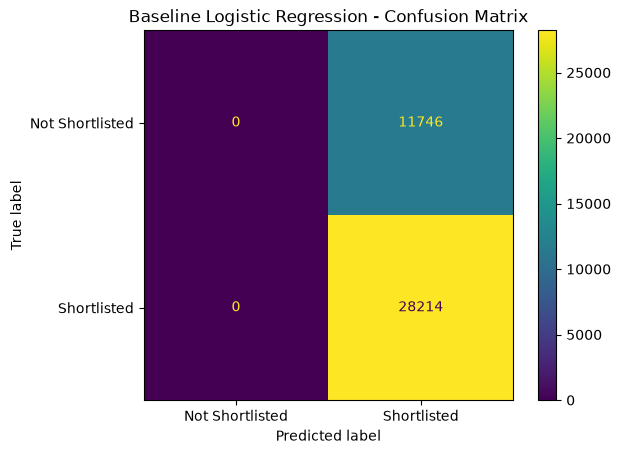

In [43]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = baseline_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Not Shortlisted", "Shortlisted"],
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Not Shortlisted", "Shortlisted"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Shortlisted", "Shortlisted"]
)

disp.plot(values_format="d")
plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.show()

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


Balanced Logistic Regression
Accuracy: 0.5214

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.33      0.60      0.42     11746
    Shortlisted       0.75      0.49      0.59     28214

       accuracy                           0.52     39960
      macro avg       0.54      0.54      0.51     39960
   weighted avg       0.62      0.52      0.54     39960



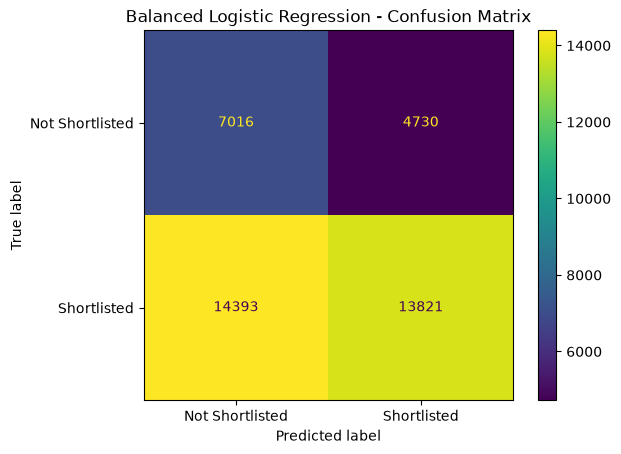

In [45]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

balanced_pred = balanced_model.predict(X_test)

print("Balanced Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, balanced_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    balanced_pred,
    labels=["Not Shortlisted", "Shortlisted"],
    zero_division=0
))

cm_balanced = confusion_matrix(
    y_test,
    balanced_pred,
    labels=["Not Shortlisted", "Shortlisted"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Not Shortlisted", "Shortlisted"]
)

disp.plot(values_format="d")
plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


Random Forest
Accuracy: 0.5309

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.33      0.57      0.42     11746
    Shortlisted       0.74      0.51      0.61     28214

       accuracy                           0.53     39960
      macro avg       0.54      0.54      0.51     39960
   weighted avg       0.62      0.53      0.55     39960



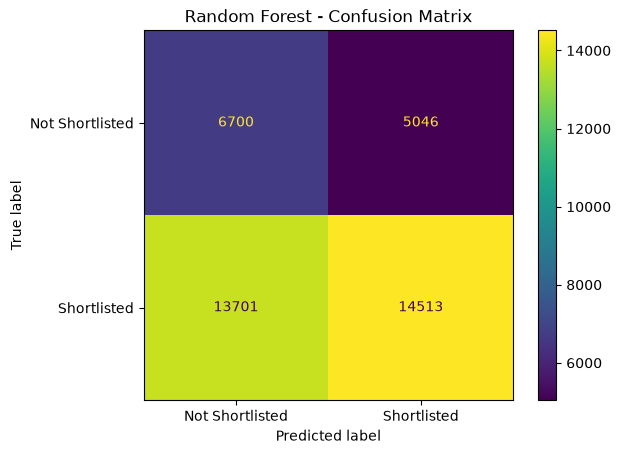

In [47]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

rf_pred = rf_model.predict(X_test)

print("Random Forest")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    labels=["Not Shortlisted", "Shortlisted"],
    zero_division=0
))

cm_rf = confusion_matrix(
    y_test,
    rf_pred,
    labels=["Not Shortlisted", "Shortlisted"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Not Shortlisted", "Shortlisted"]
)

disp.plot(values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [48]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

models = {
    "Baseline Logistic Regression": (
        baseline_model, baseline_model.predict(X_test)
    ),
    "Balanced Logistic Regression": (
        balanced_model, balanced_pred
    ),
    "Random Forest": (
        rf_model, rf_pred
    )
}

results = []

for name, (model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Not Shortlisted Recall": recall_score(
            y_test, predictions,
            pos_label="Not Shortlisted"
        ),
        "Shortlisted Recall": recall_score(
            y_test, predictions,
            pos_label="Shortlisted"
        )
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.round(4).sort_values(
        by="Macro F1", ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Balanced Accuracy,Macro F1,Not Shortlisted Recall,Shortlisted Recall
0,Random Forest,0.5309,0.5424,0.5122,0.5704,0.5144
1,Balanced Logistic Regression,0.5214,0.5436,0.5072,0.5973,0.4899
2,Baseline Logistic Regression,0.7061,0.5000,0.4139,0.0000,1.0000


In [49]:
numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

feature_comparison = df.groupby(
    "shortlisting_status"
)[numerical_columns].mean().T

feature_comparison["Absolute Difference"] = (
    feature_comparison["Shortlisted"]
    - feature_comparison["Not Shortlisted"]
).abs()

display(
    feature_comparison.sort_values(
        "Absolute Difference",
        ascending=False
    ).round(3)
)

shortlisting_status,Not Shortlisted,Shortlisted,Absolute Difference
skills_score,13.663,14.141,0.478
experience_years,1.326,1.571,0.245
projects,2.901,3.036,0.134
internships,1.412,1.541,0.129
programming_languages,2.949,3.027,0.079
resume_length_words,449.219,449.253,0.034
certifications,0.982,1.009,0.027
cgpa,7.482,7.503,0.022
soft_skills_score,6.511,6.499,0.012
hackathons,0.490,0.501,0.011


In [50]:
categorical_columns = [
    "education_level",
    "university_tier",
    "company_type"
]

for column in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"Shortlisting rate by {column}")
    print("=" * 50)

    rate_table = pd.crosstab(
        df[column],
        df["shortlisting_status"],
        normalize="index"
    ) * 100

    count_table = pd.crosstab(
        df[column],
        df["shortlisting_status"]
    )

    print("\nShortlisting percentage:")
    display(rate_table.round(2))

    print("\nCandidate counts:")
    display(count_table)


Shortlisting rate by education_level

Shortlisting percentage:


shortlisting_status,Not Shortlisted,Shortlisted
education_level,,
Bachelors,29.35,70.65
Masters,29.51,70.49
PhD,29.20,70.80



Candidate counts:


shortlisting_status,Not Shortlisted,Shortlisted
education_level,,
Bachelors,38072,91625
Masters,17789,42494
PhD,2867,6952



Shortlisting rate by university_tier

Shortlisting percentage:


...

shortlisting_status,Not Shortlisted,Shortlisted
university_tier,,
Tier 1,17599,42347
Tier 2,23513,56572
Tier 3,17616,42152



Shortlisting rate by company_type

Shortlisting percentage:


shortlisting_status,Not Shortlisted,Shortlisted
company_type,,
MNC,29.53,70.47
Mid-size,29.35,70.65
Startup,29.27,70.73



Candidate counts:


shortlisting_status,Not Shortlisted,Shortlisted
company_type,,
MNC,23660,56455
Mid-size,14636,35236
Startup,20432,49380


In [51]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_columns = [
    "education_level",
    "university_tier",
    "company_type"
]

chi_results = []

for column in categorical_columns:
    contingency_table = pd.crosstab(
        df[column],
        df["shortlisting_status"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    cramers_v = (
        (chi2 / (n * min(rows - 1, cols - 1))) ** 0.5
        if min(rows - 1, cols - 1) > 0 else 0
    )

    chi_results.append({
        "Feature": column,
        "Chi-square": chi2,
        "p-value": p_value,
        "Cramer's V": cramers_v
    })

chi_results_df = pd.DataFrame(chi_results)

display(chi_results_df.round(6))

,Feature,Chi-square,p-value,Cramer's V
0,education_level,0.663105,0.717809,0.001822
1,university_tier,0.265848,0.875532,0.001154
2,company_type,1.334821,0.513035,0.002585


In [52]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

not_shortlisted = df[
    df["shortlisting_status"] == "Not Shortlisted"
]

shortlisted = df[
    df["shortlisting_status"] == "Shortlisted"
]

numeric_results = []

for column in numerical_columns:
    group_a = not_shortlisted[column].dropna()
    group_b = shortlisted[column].dropna()

    statistic, p_value = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided"
    )

    pooled_std = np.sqrt(
        (group_a.var(ddof=1) + group_b.var(ddof=1)) / 2
    )

    standardized_difference = (
        (group_b.mean() - group_a.mean()) / pooled_std
        if pooled_std > 0 else 0
    )

    numeric_results.append({
        "Feature": column,
        "Not Shortlisted Mean": group_a.mean(),
        "Shortlisted Mean": group_b.mean(),
        "Standardized Difference": standardized_difference,
        "p-value": p_value
    })

numeric_results_df = pd.DataFrame(numeric_results)

display(
    numeric_results_df.assign(
        Absolute_Difference=lambda x:
            x["Standardized Difference"].abs()
    ).sort_values(
        "Absolute_Difference", ascending=False
    ).drop(
        columns="Absolute_Difference"
    ).round(6)
)

,Feature,Not Shortlisted Mean,Shortlisted Mean,Standardized Difference,p-value
6,experience_years,1.325899,1.571163,0.169829,0.000000
2,internships,1.412086,1.540926,0.106218,0.000000
9,skills_score,13.662793,14.140805,0.100685,0.000000
3,projects,2.901120,3.035564,0.078063,0.000000
4,programming_languages,2.948781,3.027497,0.055777,0.000000
5,certifications,0.981797,1.008960,0.027216,0.000002
1,cgpa,7.481656,7.503175,0.027011,0.000000
7,hackathons,0.490294,0.501244,0.015524,0.001658
10,soft_skills_score,6.510869,6.499183,-0.005787,0.238626
8,research_papers,0.201114,0.202239,0.002512,0.925232


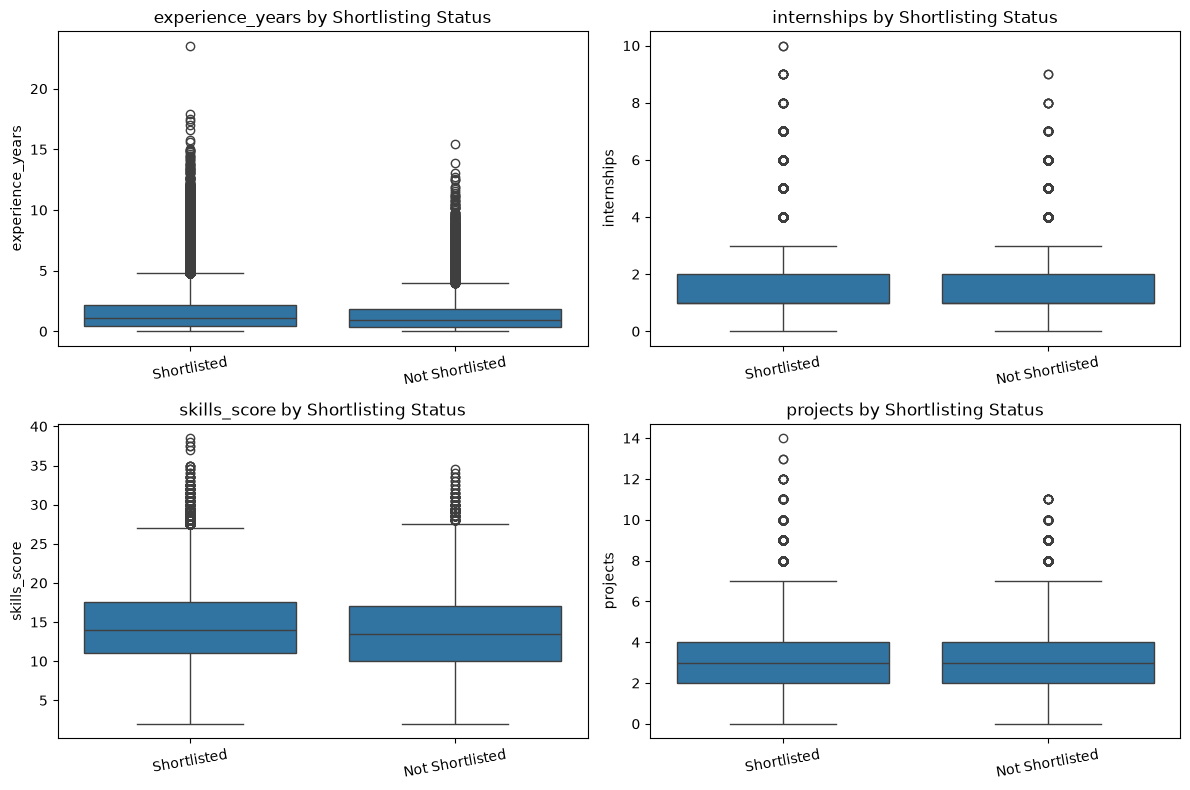

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

features_to_plot = [
    "experience_years",
    "internships",
    "skills_score",
    "projects"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(features_to_plot, axes.flatten()):
    sns.boxplot(
        data=df,
        x="shortlisting_status",
        y=column,
        ax=ax
    )
    ax.set_title(f"{column} by Shortlisting Status")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

In [54]:
print("Dataset shape:", df.shape)

print("\nTarget values:")
print(df["shortlisting_status"].value_counts())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nSample records:")
display(df.head(10))

Dataset shape: (199799, 17)

Target values:
shortlisting_status
Shortlisted        141071
Not Shortlisted     58728
Name: count, dtype: int64

Data types:


,Data Type
candidate_id,int64
age,int64
education_level,str
university_tier,str
cgpa,float64
internships,int64
projects,int64
programming_languages,int64
certifications,int64
experience_years,float64



Sample records:


,candidate_id,age,education_level,university_tier,cgpa,internships,projects,programming_languages,certifications,experience_years,hackathons,research_papers,skills_score,soft_skills_score,resume_length_words,company_type,shortlisting_status
0,1,27,Bachelors,Tier 2,8.16,2,7,2,2,0.33,0,0,21.0,5.62,409,MNC,Shortlisted
1,2,24,Bachelors,Tier 3,6.35,3,2,2,2,4.99,0,0,11.0,9.66,237,Startup,Shortlisted
2,3,33,Bachelors,Tier 3,7.78,0,2,4,2,0.93,0,0,15.0,8.12,435,Startup,Shortlisted
3,4,31,Masters,Tier 3,6.92,2,1,4,1,0.37,0,0,11.5,7.19,340,MNC,Shortlisted
4,5,28,Masters,Tier 2,8.24,3,0,1,2,0.33,0,0,5.0,4.09,371,Mid-size,Not Shortlisted
5,6,33,Bachelors,Tier 2,7.24,1,5,1,1,2.87,2,0,15.5,4.09,345,Startup,Shortlisted
6,7,25,Bachelors,Tier 2,6.96,1,4,5,0,2.83,0,0,18.0,3.41,571,Startup,Not Shortlisted
7,8,27,Masters,Tier 3,7.09,2,3,1,1,0.11,1,0,10.5,9.06,443,MNC,Not Shortlisted
8,9,30,Bachelors,Tier 3,7.02,1,4,1,1,0.44,0,1,11.5,7.21,414,MNC,Shortlisted
9,10,23,Bachelors,Tier 2,7.40,0,3,2,5,1.13,0,0,17.5,7.96,455,Startup,Shortlisted


In [55]:
from scipy.stats import mannwhitneyu

print("Candidate ID range:")
print("Minimum:", df["candidate_id"].min())
print("Maximum:", df["candidate_id"].max())
print("Unique IDs:", df["candidate_id"].nunique())

print("\nTarget distribution by ID halves:")

df["id_group"] = pd.cut(
    df["candidate_id"],
    bins=[0, 50000, 100000, 150000, 200000],
    labels=["1–50k", "50k–100k", "100k–150k", "150k–200k"]
)

id_rate = pd.crosstab(
    df["id_group"],
    df["shortlisting_status"],
    normalize="index"
) * 100

display(id_rate.round(2))

print("\nShortlisting rate by ID group:")
display(
    df.groupby("id_group", observed=False)["shortlisting_status"]
      .apply(lambda s: (s == "Shortlisted").mean() * 100)
      .round(2)
      .to_frame("Shortlisted %")
)

Candidate ID range:
Minimum: 1
Maximum: 200000
Unique IDs: 199799

Target distribution by ID halves:


shortlisting_status,Not Shortlisted,Shortlisted
id_group,,
1–50k,29.43,70.57
50k–100k,29.59,70.41
100k–150k,29.13,70.87
150k–200k,29.42,70.58



Shortlisting rate by ID group:


,Shortlisted %
id_group,
1–50k,70.57
50k–100k,70.41
100k–150k,70.87
150k–200k,70.58


In [56]:
import os

print("Current working directory:", os.getcwd())
print("\nFiles in current folder:")

for file in os.listdir():
    print(file)

Current working directory: C:\ML Projects\AI Resume Screening and Candidate Shortlisting System

Files in current folder:
.git
.gitignore
.ipynb_checkpoints
0].copy()
0].copy()#
clean_dataset.py
dataset
resume-screening-frontend
resume_screening_backend
Resume_Screening_Model.ipynb
Untitled.ipynb


In [57]:
import os

dataset_folder = "dataset"

for root, dirs, files in os.walk(dataset_folder):
    level = root.replace(dataset_folder, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

dataset/
    gold_labels.json
    phase3_labels.json
    resume_dataset_200k_with_shortlisting_status.csv
    resume_dataset_cleaned.csv
    resume_dataset_validated.csv
    scraped_jobs.json
    synthetic_profiles.json


In [58]:

import json
import os

files = [
    "synthetic_profiles.json",
    "scraped_jobs.json",
    "gold_labels.json",
    "phase3_labels.json"
]

for filename in files:
    path = os.path.join("dataset", filename)
    print(f"\n{'=' * 55}")
    print(f"FILE: {filename}")

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("Data type:", type(data).__name__)

    if isinstance(data, list):
        print("Total records:", len(data))
        if data:
            print("First record keys:",
                  list(data[0].keys()) if isinstance(data[0], dict)
                  else "Record is not a dictionary")
            print("First record sample:", str(data[0])[:700])

    elif isinstance(data, dict):
        print("Top-level keys:", list(data.keys())[:25])
        for key, value in list(data.items())[:3]:
            print(f"\n{key}:")
            if isinstance(value, list):
                print("Records:", len(value))
                if value:
                    print("Sample:", str(value[0])[:500])
            else:
                print(str(value)[:500])



FILE: synthetic_profiles.json
Data type: list
Total records: 640
First record keys: ['profile_id', 'roles', 'skills_primary', 'skills_secondary', 'experience_years', 'seniority', 'domains', 'preferences', 'career_intent', 'dealbreakers']
First record sample: {'profile_id': 1, 'roles': ['Junior Backend Engineer'], 'skills_primary': ['Python', 'Django', 'PostgreSQL'], 'skills_secondary': ['Docker', 'Redis'], 'experience_years': 1, 'seniority': 'Junior', 'domains': ['E-commerce'], 'preferences': {'locations': ['Bangalore'], 'remote': False, 'min_salary': None, 'company_sizes': []}, 'career_intent': 'Looking for early-career backend roles at product companies', 'dealbreakers': []}

FILE: scraped_jobs.json
Data type: list
Total records: 2500
First record keys: ['id', 'title', 'company', 'location', 'description', 'seniority_level', 'employment_type', 'job_function', 'industry', 'url', 'posted_at', 'scraped_at', 'role_family_hint', 'domain_hint', 'experience_years_hint', 'remote_hint']
Firs

In [59]:
import json
import os

with open("dataset/synthetic_profiles.json", encoding="utf-8") as f:
    profiles = json.load(f)

with open("dataset/scraped_jobs.json", encoding="utf-8") as f:
    jobs = json.load(f)

with open("dataset/gold_labels.json", encoding="utf-8") as f:
    gold_labels = json.load(f)

with open("dataset/phase3_labels.json", encoding="utf-8") as f:
    phase3_labels = json.load(f)

profile_ids = {str(p["profile_id"]) for p in profiles}
job_ids = {j["id"] for j in jobs}

def check_pairs(labels):
    valid = 0
    invalid = []

    for label in labels:
        pair_id = label.get("pair_id", "")
        profile_id, separator, job_id = pair_id.partition("_")

        if separator and profile_id in profile_ids and job_id in job_ids:
            valid += 1
        else:
            invalid.append(pair_id)

    return valid, invalid

for name, labels in [
    ("Gold labels", gold_labels),
    ("Phase 3 labels", phase3_labels)
]:
    valid, invalid = check_pairs(labels)
    print(f"\n{name}:")
    print("Total pairs:", len(labels))
    print("Valid profile-job pairs:", valid)
    print("Invalid pairs:", len(invalid))
    if invalid:
        print("Invalid examples:", invalid[:5])


Gold labels:
Total pairs: 108
Valid profile-job pairs: 106
Invalid pairs: 2
Invalid examples: ['21_job_20', '111_job_14']

Phase 3 labels:
Total pairs: 22465
Valid profile-job pairs: 21667
Invalid pairs: 798
Invalid examples: ['388_linkedin_4404775367', '372_linkedin_4403389903', '432_linkedin_4407420653', '405_linkedin_4405638821', '387_linkedin_4344855337']


In [60]:
def diagnose_pairs(labels, name):
    missing_profiles = []
    missing_jobs = []

    for label in labels:
        pair_id = label.get("pair_id", "")
        profile_id, separator, job_id = pair_id.partition("_")

        if not separator:
            continue

        if profile_id not in profile_ids:
            missing_profiles.append(profile_id)

        if job_id not in job_ids:
            missing_jobs.append(job_id)

    print(f"\n{name}")
    print("Pairs with missing profile IDs:", len(missing_profiles))
    print("Profile ID examples:", missing_profiles[:10])
    print("Pairs with missing job IDs:", len(missing_jobs))
    print("Job ID examples:", missing_jobs[:10])

diagnose_pairs(gold_labels, "GOLD LABELS")
diagnose_pairs(phase3_labels, "PHASE 3 LABELS")


GOLD LABELS
Pairs with missing profile IDs: 0
Profile ID examples: []
Pairs with missing job IDs: 2
Job ID examples: ['job_20', 'job_14']

PHASE 3 LABELS
Pairs with missing profile IDs: 798
Profile ID examples: ['388', '372', '432', '405', '387', '507', '440', '434', '449', '437']
Pairs with missing job IDs: 0
Job ID examples: []


In [61]:
import pandas as pd

valid_labels = []

for label in phase3_labels:
    profile_id, separator, job_id = label["pair_id"].partition("_")

    if separator and profile_id in profile_ids and job_id in job_ids:
        valid_labels.append(label)

labels_df = pd.DataFrame(valid_labels)

print("Valid matching records:", len(labels_df))
print("\nLabel source distribution:")
print(labels_df["label_source"].value_counts(dropna=False))

print("\nConfidence distribution:")
print(labels_df["confidence"].value_counts(dropna=False))

print("\nComposite score statistics:")
print(labels_df["composite"].describe().round(2))

print("\nComposite score ranges:")
print(pd.cut(
    labels_df["composite"],
    bins=[-1, 39, 59, 79, 100],
    labels=["0–39", "40–59", "60–79", "80–100"]
).value_counts().sort_index())

Valid matching records: 21667

Label source distribution:
label_source
gemini-2.5-flash-lite+static    21667
Name: count, dtype: int64

Confidence distribution:
confidence
high    21667
Name: count, dtype: int64

Composite score statistics:
count    21667.00
mean        69.50
std          7.77
min         56.00
25%         63.00
50%         67.00
75%         74.00
max         98.00
Name: composite, dtype: float64

Composite score ranges:
composite
0–39          0
40–59       524
60–79     18094
80–100     3049
Name: count, dtype: int64


In [62]:
import pandas as pd

gold_df = pd.DataFrame(gold_labels)
phase3_df = pd.DataFrame(valid_labels)

comparison = gold_df[["pair_id", "composite"]].merge(
    phase3_df[["pair_id", "composite"]],
    on="pair_id",
    how="inner",
    suffixes=("_gold", "_phase3")
)

print("Gold label records:", len(gold_df))
print("Valid Phase 3 records:", len(phase3_df))
print("Overlapping pairs:", len(comparison))

if len(comparison) > 0:
    comparison["absolute_difference"] = (
        comparison["composite_gold"] - comparison["composite_phase3"]
    ).abs()

    print(
        "Mean absolute score difference:",
        round(comparison["absolute_difference"].mean(), 2)
    )

    print(
        "Exact score agreement:",
        round(
            (comparison["composite_gold"] ==
             comparison["composite_phase3"]).mean() * 100, 2
        ),
        "%"
    )

    print(comparison.head(10).to_string(index=False))
else:
    print("No overlapping pair IDs found.")

Gold label records: 108
Valid Phase 3 records: 21667
Overlapping pairs: 45
Mean absolute score difference: 4.44
Exact score agreement: 26.67 %
                pair_id  composite_gold  composite_phase3  absolute_difference
  7_linkedin_4398675342              94                81                   13
 25_linkedin_4379080898              93                91                    2
110_linkedin_4364302087              87                83                    4
118_linkedin_4397994905              86                81                    5
  8_linkedin_4330438339              87                83                    4
138_linkedin_4399214810              85                85                    0
180_linkedin_4234624922              84                83                    1
144_linkedin_4399214810              79                62                   17
147_linkedin_4396958592              76                74                    2
170_linkedin_4393458442              61                60          

In [63]:

from scipy.stats import spearmanr

if len(comparison) > 0:
    correlation, p_value = spearmanr(
        comparison["composite_gold"],
        comparison["composite_phase3"]
    )

    differences = (
        comparison["composite_phase3"] -
        comparison["composite_gold"]
    )

    print("Overlapping pairs:", len(comparison))
    print("Spearman rank correlation:", round(correlation, 3))
    print("P-value:", round(p_value, 4))
    print("Mean signed difference (Phase 3 - Gold):",
          round(differences.mean(), 2))
    print("Pairs within 5 points:",
          f"{(differences.abs() <= 5).sum()} / {len(differences)}")
    print("Pairs within 10 points:",
          f"{(differences.abs() <= 10).sum()} / {len(differences)}")


Overlapping pairs: 45
Spearman rank correlation: 0.75
P-value: 0.0
Mean signed difference (Phase 3 - Gold): -1.82
Pairs within 5 points: 33 / 45
Pairs within 10 points: 40 / 45


In [64]:

from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report
from sklearn.base import clone
import pandas as pd

# Reuse the existing preprocessing pipeline
models_to_compare = {
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    )
}

results = []

for name, classifier in models_to_compare.items():
    model = clone(preprocessor)
    from sklearn.pipeline import Pipeline
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro")
    })

    print(f"\n{name}")
    print(classification_report(y_test, predictions, zero_division=0))

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
display(results_df.round(4))



Extra Trees
                 precision    recall  f1-score   support

Not Shortlisted       0.33      0.32      0.32     11746
    Shortlisted       0.72      0.74      0.73     28214

       accuracy                           0.61     39960
      macro avg       0.53      0.53      0.53     39960
   weighted avg       0.61      0.61      0.61     39960


Hist Gradient Boosting
                 precision    recall  f1-score   support

Not Shortlisted       0.00      0.00      0.00     11746
    Shortlisted       0.71      1.00      0.83     28214

       accuracy                           0.71     39960
      macro avg       0.35      0.50      0.41     39960
   weighted avg       0.50      0.71      0.58     39960



,Model,Accuracy,Balanced Accuracy,Macro F1
0,Extra Trees,0.6139,0.5268,0.5271
1,Hist Gradient Boosting,0.7061,0.5000,0.4139


In [65]:
import importlib.util

print("XGBoost installed:", importlib.util.find_spec("xgboost") is not None)

XGBoost installed: False


In [66]:
%pip install xgboost

  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/1f/3d/1661dd114a914a67e3f7ab66fa1382e7599c2a8c340f314ad30a3e2b4d08/xgboost-3.2.0-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB 262.6 kB/s eta 0:06:28
   ---------------------------------------- 0.2/101.7 MB 1.0 MB/s eta 0:01:40
   ---------------------------------------- 0.6/101.7 MB 3.3 MB/s eta 0:00:31
   ---------------------------------------- 1.1/101.7 MB 4.6 MB/s eta 0:00:22
    --------------------------------------- 1.8/101.7 MB 6.3 MB/s eta 0:00:16
    --------------------------------------- 2.4/101.7 MB 7.6 MB/s eta 0:00:13
   - -------------------------------------- 3.1/101.7 MB 8.6 MB/s eta 0:00:12
   - -----------------------------


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [67]:
import xgboost
print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.2.0


In [68]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, classification_report, confusion_matrix
)

# Shortlisted is the positive class
xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Encode labels as 0 and 1
y_train_xgb = (y_train == "Shortlisted").astype(int)
y_test_xgb = (y_test == "Shortlisted").astype(int)

xgb_model.fit(X_train, y_train_xgb)
xgb_predictions = xgb_model.predict(X_test)

print("XGBoost Results")
print("Accuracy:", round(accuracy_score(y_test_xgb, xgb_predictions), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test_xgb, xgb_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_test_xgb, xgb_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test_xgb,
    xgb_predictions,
    labels=[0, 1],
    target_names=["Not Shortlisted", "Shortlisted"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_xgb, xgb_predictions))


XGBoost Results
Accuracy: 0.7061
Balanced Accuracy: 0.5
Macro F1: 0.4139

Classification Report:
                 precision    recall  f1-score   support

Not Shortlisted       0.50      0.00      0.00     11746
    Shortlisted       0.71      1.00      0.83     28214

       accuracy                           0.71     39960
      macro avg       0.60      0.50      0.41     39960
   weighted avg       0.65      0.71      0.58     39960

Confusion Matrix:
[[    1 11745]
 [    1 28213]]


In [69]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, accuracy_score,
    classification_report, confusion_matrix
)

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

def make_extra_trees():
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", ExtraTreesClassifier(
            n_estimators=150,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

tuning_model = make_extra_trees()
tuning_model.fit(X_subtrain, (y_subtrain == "Shortlisted").astype(int))

val_probabilities = tuning_model.predict_proba(X_val)[:, 1]
y_val_binary = (y_val == "Shortlisted").astype(int)

threshold_results = []

for threshold in np.arange(0.30, 0.701, 0.02):
    val_predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "macro_f1": f1_score(
            y_val_binary, val_predictions, average="macro"
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val_binary, val_predictions
        )
    })

threshold_df = (
    __import__("pandas").DataFrame(threshold_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(threshold_df.head(5).round(4))

best_threshold = float(threshold_df.iloc[0]["threshold"])
print("Selected threshold:", best_threshold)

# Refit using all training data; evaluate on test only once
final_extra_trees = make_extra_trees()
final_extra_trees.fit(X_train, (y_train == "Shortlisted").astype(int))

test_probabilities = final_extra_trees.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)
y_test_binary = (y_test == "Shortlisted").astype(int)

print("\nFinal Extra Trees — Test Results")
print("Accuracy:", round(accuracy_score(y_test_binary, test_predictions), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test_binary, test_predictions), 4
))
print("Macro F1:", round(
    f1_score(y_test_binary, test_predictions, average="macro"), 4
))
print("\n", classification_report(
    y_test_binary, test_predictions,
    labels=[0, 1],
    target_names=["Not Shortlisted", "Shortlisted"],
    zero_division=0
))
print("Confusion matrix:\n", confusion_matrix(y_test_binary, test_predictions))

,threshold,macro_f1,balanced_accuracy
0,0.50,0.5277,0.5274
1,0.52,0.5235,0.5333
2,0.48,0.5077,0.5168
3,0.54,0.4961,0.5344
4,0.46,0.4779,0.5094


Selected threshold: 0.5

Final Extra Trees — Test Results
Accuracy: 0.6139
Balanced Accuracy: 0.5268
Macro F1: 0.5271

                  precision    recall  f1-score   support

Not Shortlisted       0.33      0.32      0.32     11746
    Shortlisted       0.72      0.74      0.73     28214

       accuracy                           0.61     39960
      macro avg       0.53      0.53      0.53     39960
   weighted avg       0.61      0.61      0.61     39960

Confusion matrix:
 [[ 3706  8040]
 [ 7389 20825]]


In [70]:
recommendations = recommend_jobs(profile_id=1, top_n=10)

if not recommendations.empty:
    display(recommendations)
else:
    print("No recommendations found for profile 1.")

NameError: name 'recommend_jobs' is not defined

In [74]:
def recommend_jobs(profile_id, top_n=10):
    profile_id = str(profile_id)

    matches = [
        label for label in valid_labels
        if str(label["pair_id"]).partition("_")[0] == profile_id
    ]

    if not matches:
        print(f"No valid job matches found for profile ID {profile_id}.")
        return pd.DataFrame()

    results = []

    for label in matches:
        _, _, job_id = str(label["pair_id"]).partition("_")
        job = jobs_by_id.get(job_id)

        if job is None:
            continue

        results.append({
            "profile_id": profile_id,
            "job_title": job.get("title"),
            "company": job.get("company"),
            "location": job.get("location"),
            "composite_score": label.get("composite"),
            "skills_score": label.get("skills"),
            "seniority_score": label.get("seniority"),
            "domain_score": label.get("domain"),
            "location_score": label.get("location"),
            "job_url": job.get("url")
        })

    recommendations = pd.DataFrame(results)

    if recommendations.empty:
        print("No recommendations available.")
        return recommendations

    return (
        recommendations
        .sort_values("composite_score", ascending=False)
        .drop_duplicates(subset=["job_title", "company"])
        .head(top_n)
        .reset_index(drop=True)
    )

In [75]:
recommendations = recommend_jobs(profile_id=1, top_n=10)

print("Recommendations found:", len(recommendations))

if not recommendations.empty:
    display(recommendations)
else:
    print("Profile 1 ke liye recommendations nahi mili.")

NameError: name 'jobs_by_id' is not defined

In [76]:
# Create job ID → job details lookup
jobs_by_id = {str(job["id"]): job for job in jobs}

print("Total jobs indexed:", len(jobs_by_id))
print("Sample job IDs:", list(jobs_by_id.keys())[:5])

Total jobs indexed: 2471
Sample job IDs: ['linkedin_4404078812', 'linkedin_4404068861', 'linkedin_4344450805', 'linkedin_4397799678', 'linkedin_4405972769']


In [77]:
recommendations = recommend_jobs(profile_id=1, top_n=10)

print("Recommendations found:", len(recommendations))

if not recommendations.empty:
    display(recommendations)
else:
    print("Profile 1 ke liye recommendations nahi mili.")

Recommendations found: 10


,profile_id,job_title,company,location,composite_score,skills_score,seniority_score,domain_score,location_score,job_url
0,1,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,95,95,72,68,https://www.linkedin.com/jobs/view/3918424825
1,1,Full Stack Engineer,Infosys,"Bengaluru, Karnataka, India",80,75,72,72,97,https://www.linkedin.com/jobs/view/4395957404
2,1,"Lead Software Engineer, Back End - L5 (Bangkok...",Agoda,"Pune Division, Maharashtra, India",80,92,62,72,68,https://www.linkedin.com/jobs/view/4299780194
3,1,Lead Software Engineer - Back End (FinTech) (B...,Agoda,Mumbai Metropolitan Region,78,90,62,72,68,https://www.linkedin.com/jobs/view/4299772383
4,1,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,80,85,72,68,https://www.linkedin.com/jobs/view/4374745665
5,1,"Software Engineer, Full-Stack",Loop,"New York, NY",76,85,72,72,60,https://www.linkedin.com/jobs/view/4404388134
6,1,Junior Full Stack Engineer,BolsterBiz,"Delhi, India",76,85,72,62,68,https://www.linkedin.com/jobs/view/4406539362
7,1,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,75,95,72,68,https://www.linkedin.com/jobs/view/4408213627
8,1,MERN Stack Developer,AdEngage,"Navi Mumbai, Maharashtra, India",76,75,95,72,68,https://www.linkedin.com/jobs/view/4200567634
9,1,Returnship Opportunity - Java / Angular(Fullst...,UPS,"Chennai, Tamil Nadu, India",76,75,95,72,68,https://www.linkedin.com/jobs/view/4248972535


In [78]:
# Inspect Profile 1 preferences and job-fit label coverage
profile_1 = next(
    (p for p in profiles if str(p.get("profile_id")) == "1"),
    None
)

if profile_1:
    print("PROFILE 1 DETAILS")
    display(pd.DataFrame([{
        "roles": profile_1.get("roles"),
        "primary_skills": profile_1.get("skills_primary"),
        "experience_years": profile_1.get("experience_years"),
        "seniority": profile_1.get("seniority"),
        "domains": profile_1.get("domains"),
        "preferences": profile_1.get("preferences"),
        "career_intent": profile_1.get("career_intent"),
        "dealbreakers": profile_1.get("dealbreakers")
    }]))
else:
    print("Profile 1 not found. Available IDs:", [
        p.get("profile_id") for p in profiles[:10]
    ])

PROFILE 1 DETAILS


,roles,primary_skills,experience_years,seniority,domains,preferences,career_intent,dealbreakers
0,[Junior Backend Engineer],"[Python, Django, PostgreSQL]",1,Junior,[E-commerce],"{'locations': ['Bangalore'], 'remote': False, ...",Looking for early-career backend roles at prod...,[]


In [79]:
# Diagnose relevance of current top recommendations

def check_relevance(row):
    title = str(row["job_title"]).lower()
    location = str(row["location"]).lower()

    seniority_mismatch = any(
        word in title
        for word in ["lead", "principal", "staff", "director", "head of"]
    )

    backend_match = any(
        word in title for word in ["backend", "back-end", "back end"]
    )

    preferred_location_match = any(
        city in location for city in ["bangalore", "bengaluru"]
    )

    return pd.Series({
        "backend_role": backend_match,
        "seniority_mismatch": seniority_mismatch,
        "preferred_location": preferred_location_match
    })

diagnostics = recommendations.join(
    recommendations.apply(check_relevance, axis=1)
)

display(diagnostics[[
    "job_title",
    "company",
    "location",
    "composite_score",
    "backend_role",
    "seniority_mismatch",
    "preferred_location"
]])

,job_title,company,location,composite_score,backend_role,seniority_mismatch,preferred_location
0,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,True,False,False
1,Full Stack Engineer,Infosys,"Bengaluru, Karnataka, India",80,False,False,True
2,"Lead Software Engineer, Back End - L5 (Bangkok...",Agoda,"Pune Division, Maharashtra, India",80,True,True,False
3,Lead Software Engineer - Back End (FinTech) (B...,Agoda,Mumbai Metropolitan Region,78,True,True,False
4,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,False,False,False
5,"Software Engineer, Full-Stack",Loop,"New York, NY",76,False,False,False
6,Junior Full Stack Engineer,BolsterBiz,"Delhi, India",76,False,False,False
7,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,False,False,False
8,MERN Stack Developer,AdEngage,"Navi Mumbai, Maharashtra, India",76,False,False,False
9,Returnship Opportunity - Java / Angular(Fullst...,UPS,"Chennai, Tamil Nadu, India",76,False,False,False


In [80]:
# Explainable re-ranking for Profile 1
ranked = recommendations.copy()

def ranking_adjustments(row):
    title = str(row["job_title"]).lower()
    location = str(row["location"]).lower()

    adjustment = 0
    reasons = []

    # Role relevance: profile is seeking Junior Backend Engineer roles
    if any(word in title for word in ["backend", "back-end", "back end"]):
        adjustment += 8
        reasons.append("Backend role +8")
    elif any(word in title for word in ["full stack", "full-stack"]):
        adjustment += 2
        reasons.append("Adjacent full-stack role +2")
    else:
        adjustment -= 5
        reasons.append("Less direct role match -5")

    # Seniority relevance
    if any(word in title for word in [
        "lead", "principal", "staff", "director", "head of"
    ]):
        adjustment -= 20
        reasons.append("Senior role penalty -20")
    elif "junior" in title or "entry level" in title:
        adjustment += 5
        reasons.append("Early-career role +5")

    # Location preference: Bangalore
    if "bengaluru" in location or "bangalore" in location:
        adjustment += 8
        reasons.append("Preferred location +8")

    # Explicitly flag international locations
    if "new york" in location:
        reasons.append("International location: verify eligibility")

    return pd.Series({
        "ranking_adjustment": adjustment,
        "ranking_reasons": "; ".join(reasons)
    })

ranked = ranked.join(ranked.apply(ranking_adjustments, axis=1))
ranked["adjusted_score"] = (
    ranked["composite_score"] + ranked["ranking_adjustment"]
).clip(0, 100)

ranked = ranked.sort_values(
    ["adjusted_score", "composite_score"],
    ascending=False
).reset_index(drop=True)

display(ranked[[
    "job_title", "company", "location",
    "composite_score", "ranking_adjustment",
    "adjusted_score", "ranking_reasons", "job_url"
]])

,job_title,company,location,composite_score,ranking_adjustment,adjusted_score,ranking_reasons,job_url
0,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,8,94,Backend role +8,https://www.linkedin.com/jobs/view/3918424825
1,Full Stack Engineer,Infosys,"Bengaluru, Karnataka, India",80,10,90,Adjacent full-stack role +2; Preferred locatio...,https://www.linkedin.com/jobs/view/4395957404
2,Junior Full Stack Engineer,BolsterBiz,"Delhi, India",76,7,83,Adjacent full-stack role +2; Early-career role +5,https://www.linkedin.com/jobs/view/4406539362
3,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,2,79,Adjacent full-stack role +2,https://www.linkedin.com/jobs/view/4374745665
4,"Software Engineer, Full-Stack",Loop,"New York, NY",76,2,78,Adjacent full-stack role +2; International loc...,https://www.linkedin.com/jobs/view/4404388134
5,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,2,78,Adjacent full-stack role +2,https://www.linkedin.com/jobs/view/4408213627
6,MERN Stack Developer,AdEngage,"Navi Mumbai, Maharashtra, India",76,-5,71,Less direct role match -5,https://www.linkedin.com/jobs/view/4200567634
7,Returnship Opportunity - Java / Angular(Fullst...,UPS,"Chennai, Tamil Nadu, India",76,-5,71,Less direct role match -5,https://www.linkedin.com/jobs/view/4248972535
8,"Lead Software Engineer, Back End - L5 (Bangkok...",Agoda,"Pune Division, Maharashtra, India",80,-12,68,Backend role +8; Senior role penalty -20,https://www.linkedin.com/jobs/view/4299780194
9,Lead Software Engineer - Back End (FinTech) (B...,Agoda,Mumbai Metropolitan Region,78,-12,66,Backend role +8; Senior role penalty -20,https://www.linkedin.com/jobs/view/4299772383


In [81]:
profile_1_labels = [
    label for label in valid_labels
    if str(label["pair_id"]).partition("_")[0] == "1"
]

print("Valid labeled matches for Profile 1:", len(profile_1_labels))
print(
    "Unique jobs available:",
    len({
        str(label["pair_id"]).partition("_")[2]
        for label in profile_1_labels
    })
)

Valid labeled matches for Profile 1: 63
Unique jobs available: 63


In [82]:
# Rank all 63 labeled jobs for Profile 1

profile_id = 1
profile_labels = [
    label for label in valid_labels
    if str(label["pair_id"]).partition("_")[0] == str(profile_id)
]

rows = []

for label in profile_labels:
    job_id = str(label["pair_id"]).partition("_")[2]
    job = jobs_by_id.get(job_id)

    if job is None:
        continue

    rows.append({
        "job_id": job_id,
        "job_title": job.get("title", "Unknown"),
        "company": job.get("company", "Unknown"),
        "location": job.get("location", "Unknown"),
        "composite_score": label.get("composite", 0),
        "skills_score": label.get("skills", 0),
        "seniority_score": label.get("seniority", 0),
        "domain_score": label.get("domain", 0),
        "location_score": label.get("location", 0),
        "job_url": job.get("url", "")
    })

all_ranked = pd.DataFrame(rows)

def explain_ranking(row):
    title = str(row["job_title"]).lower()
    location = str(row["location"]).lower()
    adjustment = 0
    reasons = []

    if any(word in title for word in ["backend", "back-end", "back end"]):
        adjustment += 8
        reasons.append("Backend role +8")
    elif "full stack" in title or "full-stack" in title:
        adjustment += 2
        reasons.append("Adjacent full-stack role +2")
    else:
        adjustment -= 5
        reasons.append("Less direct role match -5")

    if any(word in title for word in ["lead", "principal", "staff", "director"]):
        adjustment -= 20
        reasons.append("Senior role penalty -20")
    elif "junior" in title or "entry level" in title:
        adjustment += 5
        reasons.append("Early-career role +5")

    if "bengaluru" in location or "bangalore" in location:
        adjustment += 8
        reasons.append("Preferred location +8")

    return pd.Series({
        "ranking_adjustment": adjustment,
        "ranking_reasons": "; ".join(reasons)
    })

all_ranked = all_ranked.join(
    all_ranked.apply(explain_ranking, axis=1)
)

all_ranked["adjusted_score"] = (
    all_ranked["composite_score"] +
    all_ranked["ranking_adjustment"]
).clip(0, 100)

all_ranked = all_ranked.sort_values(
    ["adjusted_score", "composite_score"],
    ascending=False
).reset_index(drop=True)

print("Jobs ranked:", len(all_ranked))
display(all_ranked.head(10)[[
    "job_title", "company", "location",
    "composite_score", "ranking_adjustment",
    "adjusted_score", "ranking_reasons", "job_url"
]])

Jobs ranked: 63


,job_title,company,location,composite_score,ranking_adjustment,adjusted_score,ranking_reasons,job_url
0,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,8,94,Backend role +8,https://www.linkedin.com/jobs/view/3918424825
1,Full Stack Engineer,Infosys,"Bengaluru, Karnataka, India",80,10,90,Adjacent full-stack role +2; Preferred locatio...,https://www.linkedin.com/jobs/view/4395957404
2,Junior Full Stack Engineer,BolsterBiz,"Delhi, India",76,7,83,Adjacent full-stack role +2; Early-career role +5,https://www.linkedin.com/jobs/view/4406539362
3,Junior Operations Management Trainee,SAS Sales Group,"Bengaluru, Karnataka, India",75,8,83,Less direct role match -5; Early-career role +...,https://www.linkedin.com/jobs/view/4404711681
4,Sr. Backend Engineer â GenAI,Wohlig,Mumbai Metropolitan Region,74,8,82,Backend role +8,https://www.linkedin.com/jobs/view/4402470985
5,Python + Django Backend Developer,ALIQAN Technologies,"Noida, Uttar Pradesh, India",74,8,82,Backend role +8,https://www.linkedin.com/jobs/view/4372065996
6,Backend Software Engineer (Python),Emburse,"Hyderabad, Telangana, India",72,8,80,Backend role +8,https://www.linkedin.com/jobs/view/4405615545
7,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,2,79,Adjacent full-stack role +2,https://www.linkedin.com/jobs/view/4374745665
8,"Software Engineer, Full-Stack",Loop,"New York, NY",76,2,78,Adjacent full-stack role +2,https://www.linkedin.com/jobs/view/4404388134
9,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,2,78,Adjacent full-stack role +2,https://www.linkedin.com/jobs/view/4408213627


In [83]:
# Inspect actual job metadata before improving the ranking

metadata_rows = []

for _, row in all_ranked.head(10).iterrows():
    job = jobs_by_id.get(row["job_id"], {})

    metadata_rows.append({
        "job_title": job.get("title"),
        "seniority_level": job.get("seniority_level"),
        "experience_years_hint": job.get("experience_years_hint"),
        "role_family_hint": job.get("role_family_hint"),
        "domain_hint": job.get("domain_hint"),
        "remote_hint": job.get("remote_hint")
    })

display(pd.DataFrame(metadata_rows))

print("\nAvailable seniority levels:")
print(pd.Series([
    job.get("seniority_level")
    for job in jobs_by_id.values()
]).value_counts(dropna=False).head(15))

print("\nAvailable role families:")
print(pd.Series([
    job.get("role_family_hint")
    for job in jobs_by_id.values()
]).value_counts(dropna=False).head(15))

,job_title,seniority_level,experience_years_hint,role_family_hint,domain_hint,remote_hint
0,Backend Engineer (Python),Not Applicable,None,backend,None,False
1,Full Stack Engineer,Mid-Senior level,None,backend,None,False
2,Junior Full Stack Engineer,Mid-Senior level,None,fullstack,None,False
3,Junior Operations Management Trainee,Internship,None,operations,None,False
4,Sr. Backend Engineer â GenAI,Associate,None,backend,None,False
5,Python + Django Backend Developer,Director,None,mobile,None,False
6,Backend Software Engineer (Python),Mid-Senior level,None,backend,None,False
7,Full Stack Engineer,Associate,None,backend,None,False
8,"Software Engineer, Full-Stack",Mid-Senior level,None,fullstack,None,False
9,Full Stack Engineer,Entry level,None,backend,None,False



Available seniority levels:
Not Applicable      965
Mid-Senior level    550
Associate           455
Director            223
Entry level         168
Internship           99
Executive            11
Name: count, dtype: int64

Available role families:
fullstack           310
data                240
backend             231
operations          194
product             187
marketing           181
hr                  166
frontend            162
finance             159
devops              139
sales               135
non-tech            128
customer_success     89
legal                76
mobile               74
Name: count, dtype: int64


In [85]:
# Improved hybrid ranking: generated match score + metadata-aware rules

def improved_ranking(row):
    job = jobs_by_id.get(row["job_id"], {})

    title = str(job.get("title", "")).lower()
    domain = str(job.get("domain_hint", "")).lower()
    seniority = str(job.get("seniority_level", "")).lower()

    adjustment = 0
    reasons = []

    # Role-family relevance: use title and metadata together
    if any(term in title for term in ["backend", "back-end", "back end"]):
        adjustment += 10
        reasons.append("Backend title +10")
    elif domain == "backend":
        adjustment += 5
        reasons.append("Backend metadata +5")
    elif any(term in title for term in ["full stack", "full-stack", "fullstack"]):
        adjustment += 3
        reasons.append("Related full-stack role +3")
    elif domain in ["operations", "hr", "marketing", "finance", "sales",
                    "legal", "customer_success", "non-tech"]:
        adjustment -= 20
        reasons.append("Unrelated role family -20")

    # Seniority: profile is Junior with 1 year experience
    if seniority in ["director", "executive"]:
        adjustment -= 20
        reasons.append("Very senior level -20")
    elif seniority == "mid-senior level":
        adjustment -= 8
        reasons.append("Mid-senior level -8")
    elif seniority == "entry level":
        adjustment += 5
        reasons.append("Entry-level match +5")
    elif seniority == "internship":
        adjustment -= 5
        reasons.append("Internship level -5")

    # Title-based seniority signal, used as an additional caution
    if any(term in title for term in ["senior", "sr.", "lead", "principal", "staff"]):
        adjustment -= 8
        reasons.append("Senior title caution -8")
    elif "junior" in title:
        adjustment += 3
        reasons.append("Junior title +3")

    return pd.Series({
        "improved_adjustment": adjustment,
        "improved_reasons": "; ".join(reasons)
    })


improved = all_ranked.drop(
    columns=["ranking_adjustment", "ranking_reasons", "adjusted_score"],
    errors="ignore"
).copy()

improved = improved.join(improved.apply(improved_ranking, axis=1))

improved["improved_score"] = (
    improved["composite_score"] + improved["improved_adjustment"]
).clip(0, 100)

improved = improved.sort_values(
    ["improved_score", "composite_score"],
    ascending=False
).reset_index(drop=True)

display(improved.head(10)[[
    "job_title",
    "company",
    "location",
    "composite_score",
    "improved_adjustment",
    "improved_score",
    "improved_reasons",
    "job_url"
]])

,job_title,company,location,composite_score,improved_adjustment,improved_score,improved_reasons,job_url
0,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,10,96,Backend title +10,https://www.linkedin.com/jobs/view/3918424825
1,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,8,84,Related full-stack role +3; Entry-level match +5,https://www.linkedin.com/jobs/view/4408213627
2,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,3,80,Related full-stack role +3,https://www.linkedin.com/jobs/view/4374745665
3,Returnship Opportunity - Java / Angular(Fullst...,UPS,"Chennai, Tamil Nadu, India",76,3,79,Related full-stack role +3,https://www.linkedin.com/jobs/view/4248972535
4,Full Stack Software Engineer,Blink.new,"Palo Alto, CA",74,3,77,Related full-stack role +3,https://www.linkedin.com/jobs/view/4317736299
5,MERN Stack Developer,AdEngage,"Navi Mumbai, Maharashtra, India",76,0,76,,https://www.linkedin.com/jobs/view/4200567634
6,Sr. Backend Engineer â GenAI,Wohlig,Mumbai Metropolitan Region,74,2,76,Backend title +10; Senior title caution -8,https://www.linkedin.com/jobs/view/4402470985
7,Full Stack Developer,Monaqasat,"Hyderabad, Telangana, India",73,3,76,Related full-stack role +3,https://www.linkedin.com/jobs/view/4367161014
8,Full Stack Developer MERN Stack,Mintifi,"Navi Mumbai, Maharashtra, India",73,3,76,Related full-stack role +3,https://www.linkedin.com/jobs/view/4306119436
9,Full Stack Engineer,Infosys,"Bengaluru, Karnataka, India",80,-5,75,Related full-stack role +3; Mid-senior level -8,https://www.linkedin.com/jobs/view/4395957404


In [86]:
# Step 1: Evaluate the current top-10 recommendations

top10 = improved.head(10).copy()

def evaluate_job(row):
    job = jobs_by_id.get(row["job_id"], {})

    title = str(job.get("title", "")).lower()
    domain = str(job.get("domain_hint", "")).lower()
    seniority = str(job.get("seniority_level", "")).lower()
    location = str(job.get("location", "")).lower()

    backend_match = (
        any(x in title for x in ["backend", "back-end", "back end"])
        or domain == "backend"
    )

    junior_match = (
        seniority in ["entry level", "internship"]
        or "junior" in title
        or "entry level" in title
    )

    location_match = (
        "bengaluru" in location or "bangalore" in location
    )

    return pd.Series({
        "backend_match": backend_match,
        "junior_or_entry_level": junior_match,
        "preferred_location": location_match,
        "seniority_level": job.get("seniority_level"),
        "domain_hint": job.get("domain_hint")
    })

evaluation = top10.join(top10.apply(evaluate_job, axis=1))

display(evaluation[[
    "job_title",
    "company",
    "composite_score",
    "improved_score",
    "backend_match",
    "junior_or_entry_level",
    "preferred_location",
    "seniority_level",
    "domain_hint"
]])

print("\n--- Top-10 Ranking Metrics ---")
print("Backend-related jobs:", int(evaluation["backend_match"].sum()), "/ 10")
print("Junior/entry-level jobs:", int(evaluation["junior_or_entry_level"].sum()), "/ 10")
print("Preferred-location jobs:", int(evaluation["preferred_location"].sum()), "/ 10")

,job_title,company,composite_score,improved_score,backend_match,junior_or_entry_level,preferred_location,seniority_level,domain_hint
0,Backend Engineer (Python),HappyFox,86,96,True,False,False,Not Applicable,None
1,Full Stack Engineer,Planet Media® Australia Pty Ltd,76,84,False,True,False,Entry level,None
2,Full Stack Engineer,1Kosmos,77,80,False,False,False,Associate,None
3,Returnship Opportunity - Java / Angular(Fullst...,UPS,76,79,False,False,False,Not Applicable,None
4,Full Stack Software Engineer,Blink.new,74,77,False,False,False,Not Applicable,None
5,MERN Stack Developer,AdEngage,76,76,False,False,False,Not Applicable,None
6,Sr. Backend Engineer â GenAI,Wohlig,74,76,True,False,False,Associate,None
7,Full Stack Developer,Monaqasat,73,76,False,False,False,Not Applicable,None
8,Full Stack Developer MERN Stack,Mintifi,73,76,False,False,False,Associate,None
9,Full Stack Engineer,Infosys,80,75,False,False,True,Mid-Senior level,None



--- Top-10 Ranking Metrics ---
Backend-related jobs: 2 / 10
Junior/entry-level jobs: 1 / 10
Preferred-location jobs: 1 / 10


In [87]:
# Step 2: Re-rank all available jobs using profile preferences

profile = next(
    p for p in profiles
    if str(p.get("profile_id")) == "1"
)

preferred_locations = [
    str(loc).lower()
    for loc in profile.get("preferences", {}).get("locations", [])
]

profile_roles = [
    str(role).lower()
    for role in profile.get("roles", [])
]

def final_ranking_rules(row):
    job = jobs_by_id.get(row["job_id"], {})

    title = str(job.get("title", "")).lower()
    domain = str(job.get("domain_hint", "")).lower()
    seniority = str(job.get("seniority_level", "")).lower()
    location = str(job.get("location", "")).lower()

    adjustment = 0
    reasons = []

    # Role relevance
    if any(x in title for x in ["backend", "back-end", "back end"]):
        adjustment += 12
        reasons.append("Backend title +12")
    elif domain == "backend":
        adjustment += 8
        reasons.append("Backend family +8")
    elif any(x in title for x in ["full stack", "full-stack", "fullstack", "mern"]):
        adjustment += 5
        reasons.append("Related software role +5")
    elif domain in ["operations", "hr", "marketing", "finance",
                    "sales", "legal", "customer_success", "non-tech"]:
        adjustment -= 25
        reasons.append("Unrelated role -25")

    # Seniority fit
    if seniority in ["director", "executive"]:
        adjustment -= 20
        reasons.append("Senior level mismatch -20")
    elif seniority == "mid-senior level":
        adjustment -= 10
        reasons.append("Mid-senior mismatch -10")
    elif seniority == "entry level":
        adjustment += 8
        reasons.append("Entry-level match +8")
    elif seniority == "internship":
        adjustment -= 5
        reasons.append("Internship-level caution -5")

    # Title-based seniority caution
    if any(x in title for x in ["senior", "sr.", "lead", "principal", "director"]):
        adjustment -= 10
        reasons.append("Senior title caution -10")
    elif "junior" in title:
        adjustment += 4
        reasons.append("Junior title +4")

    # Preferred location
    if any(loc in location for loc in preferred_locations):
        adjustment += 8
        reasons.append("Preferred location +8")

    return pd.Series({
        "final_adjustment": adjustment,
        "final_reasons": "; ".join(reasons)
    })


final_ranked = all_rank

NameError: name 'all_rank' is not defined

In [88]:
final_ranked = all_ranked.drop(
    columns=[
        "ranking_adjustment", "ranking_reasons", "adjusted_score",
        "improved_adjustment", "improved_reasons", "improved_score"
    ],
    errors="ignore"
).copy()

final_ranked = final_ranked.join(
    final_ranked.apply(final_ranking_rules, axis=1)
)

final_ranked["final_score"] = (
    final_ranked["composite_score"] +
    final_ranked["final_adjustment"]
).clip(0, 100)

final_ranked = final_ranked.sort_values(
    ["final_score", "composite_score"],
    ascending=False
).reset_index(drop=True)

display(final_ranked.head(10)[[
    "job_title", "company", "location",
    "composite_score", "final_adjustment",
    "final_score", "final_reasons", "job_url"
]])

,job_title,company,location,composite_score,final_adjustment,final_score,final_reasons,job_url
0,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,12,98,Backend title +12,https://www.linkedin.com/jobs/view/3918424825
1,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,13,89,Related software role +5; Entry-level match +8,https://www.linkedin.com/jobs/view/4408213627
2,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,5,82,Related software role +5,https://www.linkedin.com/jobs/view/4374745665
3,MERN Stack Developer,AdEngage,"Navi Mumbai, Maharashtra, India",76,5,81,Related software role +5,https://www.linkedin.com/jobs/view/4200567634
4,Returnship Opportunity - Java / Angular(Fullst...,UPS,"Chennai, Tamil Nadu, India",76,5,81,Related software role +5,https://www.linkedin.com/jobs/view/4248972535
5,Full Stack Software Engineer,Blink.new,"Palo Alto, CA",74,5,79,Related software role +5,https://www.linkedin.com/jobs/view/4317736299
6,Full Stack Developer,Monaqasat,"Hyderabad, Telangana, India",73,5,78,Related software role +5,https://www.linkedin.com/jobs/view/4367161014
7,Full Stack Developer MERN Stack,Mintifi,"Navi Mumbai, Maharashtra, India",73,5,78,Related software role +5,https://www.linkedin.com/jobs/view/4306119436
8,Backend Engineer,Takamol Holding,"Riyadh, Saudi Arabia",65,12,77,Backend title +12,https://www.linkedin.com/jobs/view/4394754885
9,Sr. Backend Engineer â GenAI,Wohlig,Mumbai Metropolitan Region,74,2,76,Backend title +12; Senior title caution -10,https://www.linkedin.com/jobs/view/4402470985


In [89]:
# Step 3: Summarize ranking quality for Profile 1

top10_final = final_ranked.head(10).copy()

def check_recommendation(row):
    job = jobs_by_id.get(row["job_id"], {})
    title = str(job.get("title", "")).lower()
    domain = str(job.get("domain_hint", "")).lower()
    seniority = str(job.get("seniority_level", "")).lower()
    location = str(job.get("location", "")).lower()

    backend_or_fullstack = (
        any(term in title for term in [
            "backend", "back-end", "back end",
            "full stack", "full-stack", "fullstack", "mern"
        ])
        or domain in ["backend", "fullstack"]
    )

    senior_role = (
        seniority in ["director", "executive", "mid-senior level"]
        or any(term in title for term in [
            "senior", "sr.", "lead", "principal", "director"
        ])
    )

    preferred_location = any(
        loc in location for loc in preferred_locations
    )

    return pd.Series({
        "relevant_software_role": backend_or_fullstack,
        "senior_role_flag": senior_role,
        "preferred_location_match": preferred_location
    })

quality = top10_final.join(
    top10_final.apply(check_recommendation, axis=1)
)

display(quality[[
    "job_title", "location", "final_score",
    "relevant_software_role", "senior_role_flag",
    "preferred_location_match"
]])

print("\n--- Quality Summary ---")
print("Relevant software roles:", int(quality["relevant_software_role"].sum()), "/ 10")
print("Potential seniority mismatches:", int(quality["senior_role_flag"].sum()), "/ 10")
print("Preferred-location matches:", int(quality["preferred_location_match"].sum()), "/ 10")

,job_title,location,final_score,relevant_software_role,senior_role_flag,preferred_location_match
0,Backend Engineer (Python),"Hyderabad, Telangana, India",98,True,False,False
1,Full Stack Engineer,"Kochi, Kerala, India",89,True,False,False
2,Full Stack Engineer,Mumbai Metropolitan Region,82,True,False,False
3,MERN Stack Developer,"Navi Mumbai, Maharashtra, India",81,True,False,False
4,Returnship Opportunity - Java / Angular(Fullst...,"Chennai, Tamil Nadu, India",81,True,False,False
5,Full Stack Software Engineer,"Palo Alto, CA",79,True,False,False
6,Full Stack Developer,"Hyderabad, Telangana, India",78,True,False,False
7,Full Stack Developer MERN Stack,"Navi Mumbai, Maharashtra, India",78,True,False,False
8,Backend Engineer,"Riyadh, Saudi Arabia",77,True,False,False
9,Sr. Backend Engineer â GenAI,Mumbai Metropolitan Region,76,True,True,False



--- Quality Summary ---
Relevant software roles: 10 / 10
Potential seniority mismatches: 1 / 10
Preferred-location matches: 0 / 10


In [90]:
def recommend_jobs(profile_id, top_n=10):
    profile_labels = [
        label for label in valid_labels
        if str(label["pair_id"]).partition("_")[0] == str(profile_id)
    ]

    rows = []

    for label in profile_labels:
        job_id = str(label["pair_id"]).partition("_")[2]
        job = jobs_by_id.get(job_id)

        if job is None:
            continue

        rows.append({
            "job_id": job_id,
            "job_title": job.get("title", "Unknown"),
            "company": job.get("company", "Unknown"),
            "location": job.get("location", "Unknown"),
            "composite_score": label.get("composite", 0),
            "skills_score": label.get("skills", 0),
            "seniority_score": label.get("seniority", 0),
            "domain_score": label.get("domain", 0),
            "location_score": label.get("location", 0),
            "job_url": job.get("url", "")
        })

    if not rows:
        return pd.DataFrame()

    result = pd.DataFrame(rows)

    # Use the same explainable ranking rules already defined
    adjustments = result.apply(final_ranking_rules, axis=1)
    result = result.join(adjustments)

    result["final_score"] = (
        result["composite_score"] + result["final_adjustment"]
    ).clip(0, 100)

    result = result.sort_values(
        ["final_score", "composite_score"],
        ascending=False
    )

    # Avoid duplicate job listings
    result = result.drop_duplicates(
        subset=["job_title", "company"]
    ).reset_index(drop=True)

    return result.head(top_n)


# Test the reusable function
recommendations_test = recommend_jobs(profile_id=1, top_n=10)

print("Recommendations returned:", len(recommendations_test))

display(recommendations_test[[
    "job_title",
    "company",
    "location",
    "composite_score",
    "final_adjustment",
    "final_score",
    "final_reasons",
    "job_url"
]])

Recommendations returned: 10


,job_title,company,location,composite_score,final_adjustment,final_score,final_reasons,job_url
0,Backend Engineer (Python),HappyFox,"Hyderabad, Telangana, India",86,12,98,Backend title +12,https://www.linkedin.com/jobs/view/3918424825
1,Full Stack Engineer,Planet Media® Australia Pty Ltd,"Kochi, Kerala, India",76,13,89,Related software role +5; Entry-level match +8,https://www.linkedin.com/jobs/view/4408213627
2,Full Stack Engineer,1Kosmos,Mumbai Metropolitan Region,77,5,82,Related software role +5,https://www.linkedin.com/jobs/view/4374745665
3,MERN Stack Developer,AdEngage,"Navi Mumbai, Maharashtra, India",76,5,81,Related software role +5,https://www.linkedin.com/jobs/view/4200567634
4,Returnship Opportunity - Java / Angular(Fullst...,UPS,"Chennai, Tamil Nadu, India",76,5,81,Related software role +5,https://www.linkedin.com/jobs/view/4248972535
5,Full Stack Software Engineer,Blink.new,"Palo Alto, CA",74,5,79,Related software role +5,https://www.linkedin.com/jobs/view/4317736299
6,Full Stack Developer,Monaqasat,"Hyderabad, Telangana, India",73,5,78,Related software role +5,https://www.linkedin.com/jobs/view/4367161014
7,Full Stack Developer MERN Stack,Mintifi,"Navi Mumbai, Maharashtra, India",73,5,78,Related software role +5,https://www.linkedin.com/jobs/view/4306119436
8,Backend Engineer,Takamol Holding,"Riyadh, Saudi Arabia",65,12,77,Backend title +12,https://www.linkedin.com/jobs/view/4394754885
9,Sr. Backend Engineer â GenAI,Wohlig,Mumbai Metropolitan Region,74,2,76,Backend title +12; Senior title caution -10,https://www.linkedin.com/jobs/view/4402470985


In [91]:
# Test recommendation engine on multiple profiles

test_profile_ids = [1, 2, 3, 4, 5]
test_results = []

for pid in test_profile_ids:
    recs = recommend_jobs(profile_id=pid, top_n=10)

    test_results.append({
        "profile_id": pid,
        "recommendations_returned": len(recs),
        "unique_jobs": recs["job_id"].nunique() if not recs.empty else 0,
        "average_composite_score": (
            round(recs["composite_score"].mean(), 2)
            if not recs.empty else None
        ),
        "average_final_score": (
            round(recs["final_score"].mean(), 2)
            if not recs.empty else None
        ),
        "has_job_urls": (
            int(recs["job_url"].fillna("").astype(str).str.startswith("http").sum())
            if not recs.empty else 0
        )
    })

test_summary = pd.DataFrame(test_results)
display(test_summary)

,profile_id,recommendations_returned,unique_jobs,average_composite_score,average_final_score,has_job_urls
0,1,10,10,75.0,81.9,10
1,2,10,10,84.2,94.9,10
2,3,10,10,74.2,79.2,10
3,4,10,10,81.5,91.5,10
4,5,10,10,78.9,89.5,10


In [92]:
# Edge-case tests for recommendation function

# Test 1: Non-existent profile
missing_profile = recommend_jobs(profile_id=999999, top_n=10)

print("Non-existent profile result:")
print("Returned rows:", len(missing_profile))

# Test 2: top_n = 5
five_recs = recommend_jobs(profile_id=1, top_n=5)

print("\nTop-5 test:")
print("Returned rows:", len(five_recs))

# Test 3: Duplicate listing check
normal_recs = recommend_jobs(profile_id=1, top_n=10)

print("\nDuplicate check:")
print("Rows:", len(normal_recs))
print(
    "Unique job-title/company pairs:",
    normal_recs[["job_title", "company"]].drop_duplicates().shape[0]
)

Non-existent profile result:
Returned rows: 0

Top-5 test:
Returned rows: 5

Duplicate check:
Rows: 10
Unique job-title/company pairs: 10


In [93]:
# Final validation: compare recommendations across different profiles

for profile_id in [1, 2, 3, 10, 50]:
    recs = recommend_jobs(profile_id=profile_id, top_n=5)

    profile = next(
        (p for p in profiles if str(p.get("profile_id")) == str(profile_id)),
        None
    )

    print(f"\nProfile ID: {profile_id}")
    if profile:
        print("Target roles:", profile.get("roles", []))
        print("Primary skills:", profile.get("skills_primary", []))

    print("Recommendations returned:", len(recs))

    if not recs.empty:
        display(
            recs[["job_title", "company", "composite_score", "final_score"]]
        )
    else:
        print("No recommendations available.")


Profile ID: 1
Target roles: ['Junior Backend Engineer']
Primary skills: ['Python', 'Django', 'PostgreSQL']
Recommendations returned: 5


,job_title,company,composite_score,final_score
0,Backend Engineer (Python),HappyFox,86,98
1,Full Stack Engineer,Planet Media® Australia Pty Ltd,76,89
2,Full Stack Engineer,1Kosmos,77,82
3,MERN Stack Developer,AdEngage,76,81
4,Returnship Opportunity - Java / Angular(Fullst...,UPS,76,81



Profile ID: 2
Target roles: ['Junior Backend Developer']
Primary skills: ['Java', 'Spring Boot', 'MySQL']
Recommendations returned: 5


,job_title,company,composite_score,final_score
0,Java Backend Developer,The Value Maximizer,84,100
1,Software Engineer (Backend),Servify,81,100
2,Software Engineer - Backend,Infinity(YC W24),85,97
3,Backend Developer,Platform 3 Solutions,84,96
4,Backend Developer,Twixor,83,95



Profile ID: 3
Target roles: ['Junior API Developer']
Primary skills: ['Node.js', 'Express', 'MongoDB']
Recommendations returned: 5


,job_title,company,composite_score,final_score
0,Fullstack Javascript Engineer (React + Node) -...,BairesDev,85,98
1,FULL STAK DEVELOPER,Wipro,85,93
2,Full Stack Developer,Deliveright,77,82
3,Full Stack MERN Developer,NextGENi - A DotZero Company,76,81
4,Backend Engineer,Takamol Holding,67,79



Profile ID: 10
Target roles: ['API Engineer']
Primary skills: ['Go', 'gRPC', 'PostgreSQL', 'Redis', 'Docker']
Recommendations returned: 5


,job_title,company,composite_score,final_score
0,"Software Engineer, Backend- Platform",Coinbase,83,100
1,Software Development Engineer - Backend,Expound Technivo,83,95
2,"Intermediate Backend Engineer, Gitlab Delivery...",GitLab,82,94
3,Backend Developer (Golang),Adsremedy,81,93
4,"Intermediate Backend Engineer, SSCS: Supply Chain",GitLab,78,90



Profile ID: 50
Target roles: ['Junior Fullstack Developer']
Primary skills: ['React', 'Python', 'Django', 'PostgreSQL']
Recommendations returned: 5


,job_title,company,composite_score,final_score
0,Applications Developer (Location - Chennai) - ...,UPS,87,92
1,Software Developer,Sankey Solutions,77,85
2,Software Developer Engineer – SCG India,SCG,75,83
3,Python Data Modeller,Virtusa,82,82
4,Junior .Net Full Stack Developer,Hitachi Solutions India Pvt Ltd,71,80


In [94]:
# Check score saturation across multiple profiles

for profile_id in [1, 2, 3, 10, 50]:
    recs = recommend_jobs(profile_id=profile_id, top_n=10)

    if recs.empty:
        print(f"Profile {profile_id}: No recommendations")
        continue

    capped = (recs["final_score"] >= 100).sum()

    print(
        f"Profile {profile_id}: "
        f"Recommendations={len(recs)}, "
        f"Scores capped at 100={capped}, "
        f"Score range={recs['final_score'].min()}–"
        f"{recs['final_score'].max()}"
    )

Profile 1: Recommendations=10, Scores capped at 100=0, Score range=76–98
Profile 2: Recommendations=10, Scores capped at 100=2, Score range=91–100
Profile 3: Recommendations=10, Scores capped at 100=0, Score range=68–98
Profile 10: Recommendations=10, Scores capped at 100=1, Score range=87–100
Profile 50: Recommendations=10, Scores capped at 100=0, Score range=76–92


In [95]:
# Audit the ranking adjustments for Profile 2

audit = recommend_jobs(profile_id=2, top_n=10)

display(
    audit[
        [
            "job_title",
            "company",
            "composite_score",
            "final_adjustment",
            "final_score",
            "final_reasons"
        ]
    ]
)

,job_title,company,composite_score,final_adjustment,final_score,final_reasons
0,Java Backend Developer,The Value Maximizer,84,20,100,Backend title +12; Entry-level match +8
1,Software Engineer (Backend),Servify,81,20,100,Backend title +12; Entry-level match +8
2,Software Engineer - Backend,Infinity(YC W24),85,12,97,Backend title +12
3,Backend Developer,Platform 3 Solutions,84,12,96,Backend title +12
4,Backend Developer,Twixor,83,12,95,Backend title +12
5,Software Engineer 1 - Backend,Abnormal AI,81,12,93,Backend title +12
6,Backend Engineer,Proof-of-Skill,81,12,93,Backend title +12
7,"Software Engineer - Java, Spring Boot and Micr...",Apple,92,0,92,
8,Backend Engineer,Takamol Holding,80,12,92,Backend title +12
9,Java API Developer,Tetrasoft Inc.,91,0,91,


In [96]:
# Inspect job metadata for the Java/Spring Boot recommendation

for _, row in audit.iterrows():
    if "Java, Spring Boot" in str(row["job_title"]):
        job_id = row["job_id"]
        job = jobs_by_id.get(job_id, {})

        print("Job ID:", job_id)
        print("Title:", job.get("title"))
        print("Role family:", job.get("role_family_hint"))
        print("Domain:", job.get("domain_hint"))
        print("Seniority:", job.get("seniority_level"))
        print("Experience hint:", job.get("experience_years_hint"))
        break

Job ID: linkedin_4366033902
Title: Software Engineer - Java, Spring Boot and Microservices
Role family: fullstack
Domain: None
Seniority: Not Applicable
Experience hint: None


In [97]:
# Test backend-related title detection

test_titles = [
    "Software Engineer - Java, Spring Boot and Microservices",
    "Java Backend Developer",
    "Software Engineer (Backend)",
    "Full Stack MERN Developer",
    "Frontend React Developer",
    "Python Data Modeller"
]

backend_keywords = [
    "backend", "back-end", "back end",
    "api developer", "api engineer",
    "spring boot", "microservices"
]

for title in test_titles:
    title_lower = title.lower()
    is_backend = any(keyword in title_lower for keyword in backend_keywords)

    print(f"{title} -> Backend match: {is_backend}")

Software Engineer - Java, Spring Boot and Microservices -> Backend match: True
Java Backend Developer -> Backend match: True
Software Engineer (Backend) -> Backend match: True
Full Stack MERN Developer -> Backend match: False
Frontend React Developer -> Backend match: False
Python Data Modeller -> Backend match: False


In [98]:
def final_ranking_rules(row):
    job = jobs_by_id.get(row["job_id"], {})

    title = str(job.get("title") or row.get("job_title") or "").lower()
    domain = str(job.get("domain_hint") or "").lower()
    seniority = str(job.get("seniority_level") or "").lower()
    location = str(job.get("location") or row.get("location") or "").lower()

    adjustment = 0
    reasons = []

    # Backend relevance: title takes priority over imperfect metadata
    backend_keywords = [
        "backend", "back-end", "back end",
        "api developer", "api engineer",
        "spring boot", "microservices"
    ]

    if any(keyword in title for keyword in backend_keywords):
        adjustment += 12
        reasons.append("Backend-related title +12")
    elif "backend" in domain:
        adjustment += 8
        reasons.append("Backend domain +8")

    # Related full-stack roles
    elif any(keyword in title for keyword in [
        "full stack", "full-stack", "fullstack", "mern"
    ]):
        adjustment += 5
        reasons.append("Related full-stack role +5")

    # Clearly unrelated domains
    elif any(keyword in domain for keyword in [
        "operations", "human resources", "marketing",
        "finance", "sales", "legal", "customer success"
    ]):
        adjustment -= 25
        reasons.append("Unrelated domain -25")

    # Seniority adjustments
    if any(level in seniority for level in ["director", "executive"]):
        adjustment -= 20
        reasons.append("Senior leadership level -20")
    elif "mid-senior" in seniority:
        adjustment -= 10
        reasons.append("Mid-senior level -10")
    elif "entry level" in seniority:
        adjustment += 8
        reasons.append("Entry-level match +8")
    elif "internship" in seniority:
        adjustment -= 5
        reasons.append("Internship level -5")

    # Title-level seniority hints
    if any(keyword in title for keyword in [
        "senior", "sr.", "lead", "principal", "director"
    ]):
        adjustment -= 10
        reasons.append("Senior title -10")
    elif "junior" in title:
        adjustment += 4
        reasons.append("Junior title +4")

    # Preferred location
    profile = next(
        (
            p for p in profiles
            if str(p.get("profile_id")) == str(row.get("profile_id"))
        ),
        {}
    )
    preferred_locations = (
        profile.get("preferences", {}).get("locations", [])
        if isinstance(profile.get("preferences"), dict)
        else []
    )

    if any(
        str(place).lower() in location
        for place in preferred_locations
    ):
        adjustment += 8
        reasons.append("Preferred location +8")

    return pd.Series({
        "final_adjustment": adjustment,
        "final_reasons": "; ".join(reasons)
    })

In [99]:
# Test updated ranking rule on the Java/Spring Boot job

test_row = audit[
    audit["job_title"].str.contains(
        "Java, Spring Boot", case=False, na=False
    )
].iloc[0]

result = final_ranking_rules(test_row)

print("Job:", test_row["job_title"])
print("Original composite score:", test_row["composite_score"])
print("Ranking adjustment:", result["final_adjustment"])
print("Adjustment reasons:", result["final_reasons"])

Job: Software Engineer - Java, Spring Boot and Microservices
Original composite score: 92
Ranking adjustment: 12
Adjustment reasons: Backend-related title +12


In [100]:
# Rebuild recommendations using the updated ranking rule

audit_updated = recommend_jobs(profile_id=2, top_n=10)

display(
    audit_updated[
        [
            "job_title",
            "company",
            "composite_score",
            "final_adjustment",
            "final_score",
            "final_reasons"
        ]
    ]
)

,job_title,company,composite_score,final_adjustment,final_score,final_reasons
0,"Software Engineer - Java, Spring Boot and Micr...",Apple,92,12,100,Backend-related title +12
1,Java API Developer,Tetrasoft Inc.,91,12,100,Backend-related title +12
2,Java Backend Developer,The Value Maximizer,84,20,100,Backend-related title +12; Entry-level match +8
3,Software Engineer (Backend),Servify,81,20,100,Backend-related title +12; Entry-level match +8
4,Software Engineer - Backend,Infinity(YC W24),85,12,97,Backend-related title +12
5,Backend Developer,Platform 3 Solutions,84,12,96,Backend-related title +12
6,Backend Developer,Twixor,83,12,95,Backend-related title +12
7,Software Engineer 1 - Backend,Abnormal AI,81,12,93,Backend-related title +12
8,Backend Engineer,Proof-of-Skill,81,12,93,Backend-related title +12
9,Backend Engineer,Takamol Holding,80,12,92,Backend-related title +12


In [101]:
# Final consistency check after ranking-rule update

for profile_id in [1, 2, 3, 10, 50]:
    recs = recommend_jobs(profile_id=profile_id, top_n=10)

    unique_pairs = recs[["job_title", "company"]].drop_duplicates().shape[0]

    print(
        f"Profile {profile_id}: "
        f"rows={len(recs)}, "
        f"unique job/company pairs={unique_pairs}, "
        f"duplicate pairs={len(recs) - unique_pairs}"
    )

Profile 1: rows=10, unique job/company pairs=10, duplicate pairs=0
Profile 2: rows=10, unique job/company pairs=10, duplicate pairs=0
Profile 3: rows=10, unique job/company pairs=10, duplicate pairs=0
Profile 10: rows=10, unique job/company pairs=10, duplicate pairs=0
Profile 50: rows=10, unique job/company pairs=10, duplicate pairs=0


In [102]:
# Inspect recommendation and ground-truth label mapping

print("Recommendation columns:")
print(recs.columns.tolist())

print("\nSample recommendation job IDs:")
print(recs["job_id"].head().tolist())

print("\nSample valid label pair IDs:")
print([label["pair_id"] for label in valid_labels[:5]])

print("\nSample Phase 3 label:")
print(phase3_labels[0])

Recommendation columns:
['job_id', 'job_title', 'company', 'location', 'composite_score', 'skills_score', 'seniority_score', 'domain_score', 'location_score', 'job_url', 'final_adjustment', 'final_reasons', 'final_score']

Sample recommendation job IDs:
['linkedin_4248785248', 'linkedin_4306126315', 'linkedin_4297845079', 'linkedin_4404172755', 'linkedin_4392402896']

Sample valid label pair IDs:
['19_linkedin_4374745665', '39_linkedin_4306130230', '88_linkedin_4370337080', '20_linkedin_4400516267', '146_linkedin_4400586281']

Sample Phase 3 label:
{'pair_id': '19_linkedin_4374745665', 'skills': 85, 'seniority': 78, 'domain': 90, 'location': 68, 'composite': 80, 'overqualified': True, 'matches': ['Backend Engineer', 'Node.js'], 'gaps': ['React', 'Frontend Development'], 'label_source': 'gemini-2.5-flash-lite+static', 'confidence': 'high'}


In [103]:
# Prepare profile-job relevance labels for evaluation

label_rows = []

for label in phase3_labels:
    profile_part, separator, job_id = label["pair_id"].partition("_")

    if not separator:
        continue

    try:
        profile_id = int(profile_part)
    except (TypeError, ValueError):
        continue

    if profile_id not in {
        int(p["profile_id"]) for p in profiles
    }:
        continue

    if job_id not in jobs_by_id:
        continue

    label_rows.append({
        "profile_id": profile_id,
        "job_id": job_id,
        "relevance_score": float(label["composite"])
    })

evaluation_labels = pd.DataFrame(label_rows)

print("Valid evaluation labels:", len(evaluation_labels))
print("Unique profiles:", evaluation_labels["profile_id"].nunique())
print("Unique jobs:", evaluation_labels["job_id"].nunique())
print("Duplicate profile-job pairs:",
      evaluation_labels.duplicated(["profile_id", "job_id"]).sum())

display(evaluation_labels.head())

Valid evaluation labels: 21667
Unique profiles: 621
Unique jobs: 2127
Duplicate profile-job pairs: 0


,profile_id,job_id,relevance_score
0,19,linkedin_4374745665,80.0
1,39,linkedin_4306130230,82.0
2,88,linkedin_4370337080,73.0
3,20,linkedin_4400516267,73.0
4,146,linkedin_4400586281,71.0


In [104]:
import numpy as np

# Diagnostic evaluation against generated Phase 3 labels
K = 10
RELEVANCE_THRESHOLD = 70

label_lookup = evaluation_labels.set_index(
    ["profile_id", "job_id"]
)["relevance_score"]

ndcg_values = []
precision_values = []
evaluated_profiles = 0

def dcg_at_k(scores, k=10):
    scores = np.asarray(scores[:k], dtype=float)
    if len(scores) == 0:
        return 0.0
    discounts = np.log2(np.arange(2, len(scores) + 2))
    gains = np.power(2.0, scores / 10.0) - 1
    return float(np.sum(gains / discounts))

for profile_id in sorted(evaluation_labels["profile_id"].unique()):
    recs = recommend_jobs(profile_id=int(profile_id), top_n=K)

    if recs.empty:
        continue

    actual_scores = []
    for job_id in recs["job_id"]:
        key = (int(profile_id), job_id)
        actual_scores.append(label_lookup.get(key, np.nan))

    evaluated = [
        (job_id, score)
        for job_id, score in zip(recs["job_id"], actual_scores)
        if pd.notna(score)
    ]

    if not evaluated:
        continue

    scores = [score for _, score in evaluated]

    precision_values.append(
        sum(score >= RELEVANCE_THRESHOLD for score in scores) / K
    )

    ideal_scores = sorted(
        evaluation_labels.loc[
            evaluation_labels["profile_id"] == profile_id,
            "relevance_score"
        ].tolist(),
        reverse=True
    )[:K]

    ideal_dcg = dcg_at_k(ideal_scores, K)
    actual_dcg = dcg_at_k(scores, K)

    if ideal_dcg > 0:
        ndcg_values.append(actual_dcg / ideal_dcg)

    evaluated_profiles += 1

print("Profiles evaluated:", evaluated_profiles)
print(f"Precision@{K} (relevance >= {RELEVANCE_THRESHOLD}):",
      round(float(np.mean(precision_values)), 4)
      if precision_values else "N/A")
print(f"NDCG@{K}:", round(float(np.mean(ndcg_values)), 4)
      if ndcg_values else "N/A")
print("Evaluation type: Diagnostic only; labels overlap with ranking inputs.")

Profiles evaluated: 621
Precision@10 (relevance >= 70): 0.5876
NDCG@10: 0.9172
Evaluation type: Diagnostic only; labels overlap with ranking inputs.
